# CSET485 – AI and Society · Assignment 1
## Stress-testing a predictive model on the **Adult Census Income** dataset

**Task.** Predict whether a person earns >\$50K, then deliberately break the model: Simpson's paradox, omitted-variable bias, confident-error analysis, and a fairness trade-off sweep.

**How to run.** Put `adult.csv` (Kaggle version, columns like `education.num`) in the same folder as this notebook, set `ROLL_LAST3` in the next cell, then *Kernel → Restart & Run All*. Every number quoted in the PDF report is produced by this notebook; all tables are saved to `results/` and all figures to `figures/`.

| Section | Content |
|---|---|
| 0 | Configuration & imports |
| 1 | Data preprocessing (missing values, encoding, scaling, outliers, split) |
| Part 1 | Linear (OLS) vs Logistic model, threshold comparison, mismatch analysis |
| Part 2.1 | Simpson's-paradox hunt |
| Part 2.2 | Omitted-variable bias |
| Part 2.3 | Adversarial subset (confident wrong predictions) |
| Part 2.4 | Fairness trade-off sweep (DP / EO / PP) |
| Part 3–4 | "Numbers cheat-sheet" – every figure needed for the written answers |

## 0. Configuration & imports

In [1]:
# ===================== EDIT THIS =====================
ROLL_LAST3   = 123          # <-- last 3 digits of YOUR roll number (used as random_state)
DATA_PATH    = "/mnt/data/adult.csv"  # path to the Adult Census Income csv
# =====================================================

RANDOM_STATE = ROLL_LAST3
TEST_SIZE    = 0.30         # 70 / 30 split as required
ALPHA        = 0.05

import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)

RESULTS = {}     # every number needed for the written report is collected here
def save_fig(name):
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
def save_table(d, name):
    d.to_csv(f"results/{name}.csv")
print("random_state =", RANDOM_STATE)

random_state = 123


## 1. Data preprocessing
Every decision below is documented (what was done and *why*) because the assignment requires it in the report.

### 1.1 Load data

In [2]:
UCI_COLS = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation",
            "relationship","race","sex","capital_gain","capital_loss","hours_per_week","native_country","income"]

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"{DATA_PATH} not found. Download the Adult Census Income csv (Kaggle) and put it next to this notebook.")

df_raw = pd.read_csv(DATA_PATH, skipinitialspace=True)
if "income" not in [c.lower() for c in df_raw.columns]:            # head-less UCI file (adult.data)
    df_raw = pd.read_csv(DATA_PATH, header=None, names=UCI_COLS, skipinitialspace=True)

df = df_raw.copy()
df.columns = df.columns.str.strip().str.replace(".", "_", regex=False).str.replace("-", "_", regex=False)
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].astype(str).str.strip()
print("Raw shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype").T)

Raw shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
dtype,int64,object,int64,object,int64,object,object,object,object,object,int64,int64,int64,object,object


### 1.2 Missing values
In this dataset missing values are coded as `"?"` (not `NaN`) and occur only in three categorical columns.
**Decision:** convert `?` → `NaN`, then keep those rows and flag the missing entries with an explicit indicator/category (`job_info_missing`, `native = Unknown`).
*Why:* the missingness is not random (people with unknown occupation/workclass have very different income rates – see below), so deleting them would bias the sample and throw away ~7 % of the data; an explicit indicator lets the model use the information.

In [3]:
df = df.replace("?", np.nan)
miss = df.isna().sum().to_frame("n_missing"); miss["pct"] = (miss.n_missing / len(df) * 100).round(2)
display(miss[miss.n_missing > 0])

df["income_bin"] = df["income"].str.startswith(">50K").astype(int)        # 1 = >50K, 0 = <=50K
print("\nIncome>50K rate when occupation is missing vs present:")
display(df.groupby(df.occupation.isna())["income_bin"].agg(["mean","count"]).rename(index={True:"occupation missing", False:"occupation present"}).round(3))

n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_dup} exact duplicate rows -> {len(df)} rows remain")
RESULTS["preproc"] = dict(n_raw=len(df_raw), n_dup=int(n_dup), n_final=len(df),
                          missing_occupation=int(miss.loc["occupation","n_missing"]) if "occupation" in miss.index else None)

,n_missing,pct
workclass,1836,5.64
occupation,1843,5.66
native_country,583,1.79



Income>50K rate when occupation is missing vs present:


,mean,count
occupation,,
occupation present,0.249,30718
occupation missing,0.104,1843


Dropped 24 exact duplicate rows -> 32537 rows remain


### 1.3 Feature selection, grouping and categorical encoding
| Column | Treatment | Reason |
|---|---|---|
| `fnlwgt` | dropped from the feature set | census sampling weight, not a property of the person |
| `education` | dropped | duplicate of `education_num` (ordinal years) |
| `relationship` | dropped | almost a copy of `marital_status` + `sex` (Husband/Wife leak gender) → severe collinearity |
| `workclass` | 3 groups: Private, Self-employed, Government | coarser groups, sparse levels merged |
| `workclass` / `occupation` missing (`?`) and `Never-worked`/`Without-pay` | one indicator `job_info_missing` (1,857 rows); these rows otherwise sit in the reference categories | workclass and occupation are missing *together* in ~all cases, so two separate `Unknown` dummies are (almost) perfectly collinear and stop the logit from converging (coefficients of ±18). `Never-worked`/`Without-pay` (21 rows) have zero >50K cases and are merged here to avoid perfect separation |
| `marital_status` | 3 groups: Married, Never-married, Previously-married | 7 raw levels are sparse |
| `occupation` | 13 levels; `Armed-Forces`→`Protective-serv`, `Priv-house-serv`→`Other-service` | tiny cells (<0.5 %) cause unstable coefficients |
| `race` | White, Black, Asian-Pac-Islander, Other (incl. Amer-Indian-Eskimo) | small cells |
| `native_country` | US / Non-US / Unknown | 41 levels, 90 % are US |
| `sex` | `sex_Male` dummy | binary |

**Encoding:** one-hot with an explicit reference category (`drop_first` by choice, not alphabetically) so coefficients are directly interpretable: reference = Private, Never-married, Adm-clerical, White, Female, US.

In [4]:
df["workclass_grp"] = df["workclass"].map({"Private":"Private","Self-emp-not-inc":"Self-employed","Self-emp-inc":"Self-employed",
                                          "Local-gov":"Government","State-gov":"Government","Federal-gov":"Government"}).fillna("Unknown_NoPay")
df["marital_grp"]   = df["marital_status"].map({"Married-civ-spouse":"Married","Married-AF-spouse":"Married",
                                               "Never-married":"Never-married"}).fillna("Previously-married")
df["occupation_grp"] = (df["occupation"].fillna("Unknown")
                        .replace({"Armed-Forces":"Protective-serv","Priv-house-serv":"Other-service"}))
df["race_grp"]   = df["race"].map({"White":"White","Black":"Black","Asian-Pac-Islander":"Asian-Pac-Islander"}).fillna("Other")
df["native_grp"] = np.where(df["native_country"].isna(), "Unknown", np.where(df["native_country"]=="United-States", "US", "Non-US"))
print("Workclass groups :", df.workclass_grp.value_counts().to_dict())
print("Marital groups   :", df.marital_grp.value_counts().to_dict())
print("Race groups      :", df.race_grp.value_counts().to_dict())
print("Native groups    :", df.native_grp.value_counts().to_dict())

Workclass groups : {'Private': 22673, 'Government': 4351, 'Self-employed': 3656, 'Unknown_NoPay': 1857}
Marital groups   : {'Married': 14993, 'Never-married': 10667, 'Previously-married': 6877}
Race groups      : {'White': 27795, 'Black': 3122, 'Asian-Pac-Islander': 1038, 'Other': 582}
Native groups    : {'US': 29153, 'Non-US': 2802, 'Unknown': 582}


### 1.4 Outliers
Numeric columns are inspected with the 1.5×IQR rule. **Decision:** *no rows are deleted*. The extreme values are real people (e.g. 99 hours/week, \$99,999 capital gain), and deleting high earners would bias a model whose target is high income.
Instead the two heavy-tailed monetary columns get `log(1+x)` to compress the tail; `99999` in `capital_gain` is a known census **top-code** (censoring value) and is documented but kept.
`age`, `education_num` and `hours_per_week` are bounded and left as-is (then standardised).

,min,median,max,skew,IQR_outliers,pct_nonzero
age,17,37.0,90,0.56,142,100.00
education_num,1,10.0,16,-0.31,1193,100.00
hours_per_week,1,40.0,99,0.23,9002,100.00
capital_gain,0,0.0,99999,11.95,2712,8.34
capital_loss,0,0.0,4356,4.59,1519,4.67


capital_gain == 99999 (top-coded): 159 rows, of which >50K: 100.0%


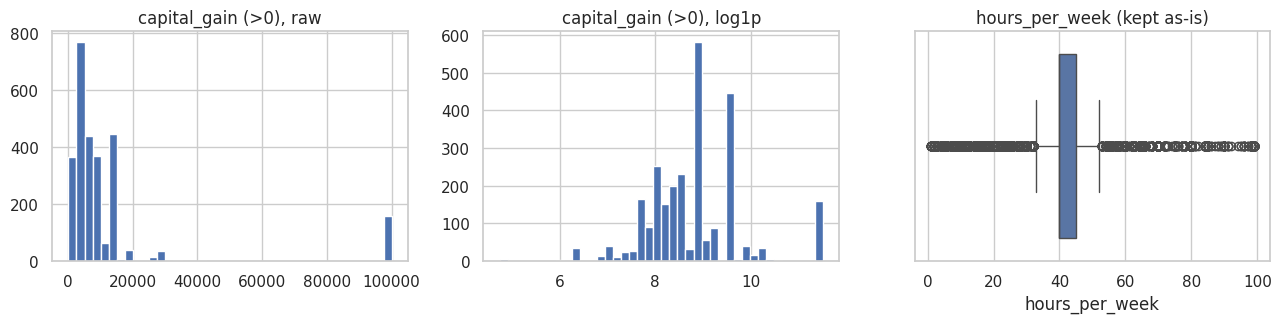

In [5]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

num_raw = ["age","education_num","hours_per_week","capital_gain","capital_loss"]
out_tbl = pd.DataFrame({
    "min": df[num_raw].min(), "median": df[num_raw].median(), "max": df[num_raw].max(),
    "skew": df[num_raw].skew().round(2),
    "IQR_outliers": [iqr_outliers(df[c]) for c in num_raw],
    "pct_nonzero": [(df[c] != 0).mean()*100 for c in num_raw]}).round(2)
display(out_tbl)
n_topcode = int((df.capital_gain == 99999).sum())
print(f"capital_gain == 99999 (top-coded): {n_topcode} rows, of which >50K: {df.loc[df.capital_gain==99999,'income_bin'].mean():.1%}")
save_table(out_tbl, "outlier_summary")

df["capital_gain_log"] = np.log1p(df.capital_gain)
df["capital_loss_log"] = np.log1p(df.capital_loss)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(pd.to_numeric(df.loc[df.capital_gain>0, "capital_gain"]), bins=40); ax[0].set_title("capital_gain (>0), raw")
ax[1].hist(pd.to_numeric(df.loc[df.capital_gain>0, "capital_gain_log"]), bins=40); ax[1].set_title("capital_gain (>0), log1p")
sns.boxplot(x=df.hours_per_week, ax=ax[2]); ax[2].set_title("hours_per_week (kept as-is)")
plt.tight_layout(); save_fig("01_outliers"); plt.show()
RESULTS["preproc"]["n_topcode"] = n_topcode

In [6]:
NUM_COLS = ["age","education_num","hours_per_week","capital_gain_log","capital_loss_log"]
# column -> (dummy prefix, reference category, extra levels dropped because they are covered by job_info_missing)
REFS = {"workclass_grp":("work","Private",["Unknown_NoPay"]), "marital_grp":("marital","Never-married",[]), "occupation_grp":("occ","Adm-clerical",["Unknown"]),
        "race_grp":("race","White",[]), "sex":("sex","Female",[]), "native_grp":("native","US",[])}

X = df[NUM_COLS].copy()
for col, (pre, ref, extra) in REFS.items():
    dm = pd.get_dummies(df[col], prefix=pre, dtype=float)
    X = X.join(dm.drop(columns=[f"{pre}_{v}" for v in [ref] + extra]))
X["job_info_missing"] = ((df.workclass_grp == "Unknown_NoPay") | (df.occupation_grp == "Unknown")).astype(float)
X.columns = [c.replace("/", "_") for c in X.columns]
y = df["income_bin"]
print("Design matrix:", X.shape, "| positive rate:", round(y.mean(), 4))
print(list(X.columns))

Design matrix: (32537, 27) | positive rate: 0.2409
['age', 'education_num', 'hours_per_week', 'capital_gain_log', 'capital_loss_log', 'work_Government', 'work_Self-employed', 'marital_Married', 'marital_Previously-married', 'occ_Craft-repair', 'occ_Exec-managerial', 'occ_Farming-fishing', 'occ_Handlers-cleaners', 'occ_Machine-op-inspct', 'occ_Other-service', 'occ_Prof-specialty', 'occ_Protective-serv', 'occ_Sales', 'occ_Tech-support', 'occ_Transport-moving', 'race_Asian-Pac-Islander', 'race_Black', 'race_Other', 'sex_Male', 'native_Non-US', 'native_Unknown', 'job_info_missing']


### 1.5 Train/test split and feature scaling
* 70 % / 30 % split with `random_state = ROLL_LAST3` (no stratification was requested; the class balance is checked below).
* **Scaling:** the five continuous columns are z-scored with a `StandardScaler` **fitted on the training set only** (avoids leakage) and then applied to the test set. Dummy variables are left as 0/1. Consequently a coefficient on a continuous variable is "change in log-odds (or probability) per +1 SD"; on a dummy it is "vs. the reference category".
* For the whole-dataset analyses in Part 2.1 the same (train-fitted) scaler is applied to every row so that coefficients from the full model and both subgroups are on the same scale.

In [7]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(Xtr[NUM_COLS])
def scale(d):
    d = d.copy(); d[NUM_COLS] = scaler.transform(d[NUM_COLS]); return d
Xtr_s, Xte_s, Xall_s = scale(Xtr), scale(Xte), scale(X)
Xtr_c = sm.add_constant(Xtr_s, has_constant="add"); Xte_c = sm.add_constant(Xte_s, has_constant="add")
df_te = df.loc[Xte.index]           # human-readable version of the test rows (for demographic analysis)

print(f"train n={len(Xtr):,}  test n={len(Xte):,}")
print(f"positive rate  train={ytr.mean():.4f}  test={yte.mean():.4f}  (majority-class accuracy on test = {1-yte.mean():.4f})")

summary = pd.DataFrame([
 ["Missing values", "'?' -> NaN; missing workclass/occupation -> one 'job_info_missing' indicator, missing native_country -> 'Unknown' level; no rows deleted; exact duplicates dropped", "Missingness is informative; keeps data"],
 ["Categorical encoding", "Grouped rare levels, one-hot with explicit reference category", "Avoid sparse/unstable coefficients; interpretable"],
 ["Feature scaling", "StandardScaler on 5 continuous columns, fitted on train only", "Comparable coefficients, no leakage"],
 ["Outliers", "Kept (real people); log1p on capital_gain/loss; 99999 top-code documented", "Deleting high earners would bias the target"],
 ["Dropped columns", "fnlwgt, education, relationship", "Sampling weight / duplicate / collinear + gender leak"],
 ["Split", f"70/30, random_state={RANDOM_STATE}", "Assignment requirement"]],
 columns=["Step","What was done","Why"])
display(summary); save_table(summary.set_index("Step"), "preprocessing_summary")
RESULTS["split"] = dict(n_train=len(Xtr), n_test=len(Xte), pos_rate=float(y.mean()), pos_rate_test=float(yte.mean()))

train n=22,775  test n=9,762
positive rate  train=0.2424  test=0.2375  (majority-class accuracy on test = 0.7625)


,Step,What was done,Why
0,Missing values,'?' -> NaN; missing workclass/occupation -> on...,Missingness is informative; keeps data
1,Categorical encoding,"Grouped rare levels, one-hot with explicit ref...",Avoid sparse/unstable coefficients; interpretable
2,Feature scaling,"StandardScaler on 5 continuous columns, fitted...","Comparable coefficients, no leakage"
3,Outliers,Kept (real people); log1p on capital_gain/loss...,Deleting high earners would bias the target
4,Dropped columns,"fnlwgt, education, relationship",Sampling weight / duplicate / collinear + gend...
5,Split,"70/30, random_state=123",Assignment requirement


### 1.6 Quick look at the data (context for later sections)

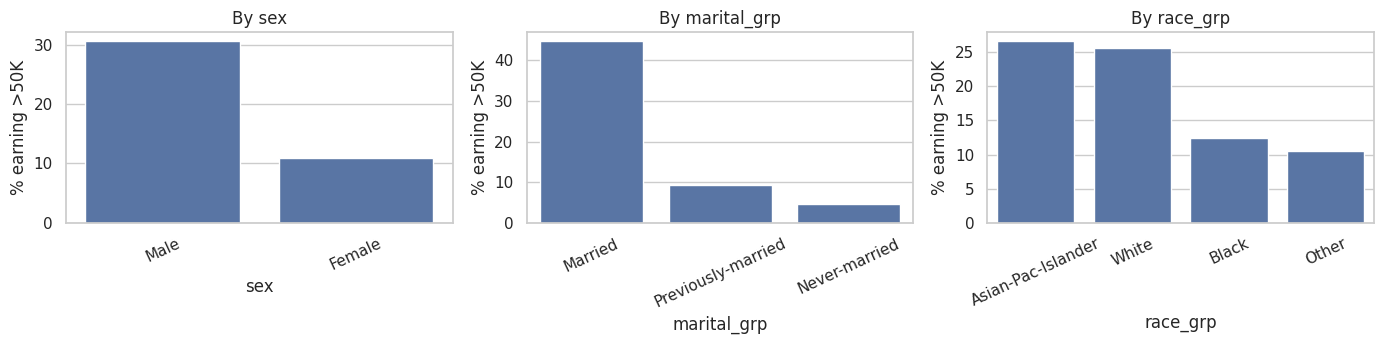

rate             n       
sex                Female   Male Female   Male
marital_grp                                   
Married             0.455  0.446   1671  13322
Never-married       0.035  0.055   4760   5907
Previously-married  0.058  0.155   4331   2546

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col in zip(ax, ["sex", "marital_grp", "race_grp"]):
    r = df.groupby(col)["income_bin"].mean().sort_values(ascending=False)
    sns.barplot(x=r.index, y=r.values*100, ax=a, color="#4C72B0"); a.set_ylabel("% earning >50K"); a.set_title(f"By {col}")
    a.tick_params(axis="x", rotation=25)
plt.tight_layout(); save_fig("02_income_rates"); plt.show()
display(df.groupby(["sex","marital_grp"])["income_bin"].agg(rate="mean", n="count").round(3).unstack(0))

---
# Part 1 – Build: Linear (OLS) vs Logistic
* **Model A** – OLS on the 0/1 income label (a *linear probability model*); its prediction is a continuous score. We threshold it at **its own median** on the test set.
* **Model B** – Logistic regression; predicted probability thresholded at **0.5**.

Both models are fitted with `statsmodels` (no regularisation) so that coefficients, standard errors and CIs are available for Part 2.

In [9]:
ols   = sm.OLS(ytr, Xtr_c).fit()
logit = sm.Logit(ytr, Xtr_c).fit(disp=0, maxiter=300)
assert logit.mle_retvals["converged"], "Logit did not converge – check for (quasi-)separation / collinear dummies"
print("Logit converged:", logit.mle_retvals["converged"], "| pseudo-R2 =", round(logit.prsquared, 4), "| OLS R2 =", round(ols.rsquared, 4))

coefs = pd.DataFrame({"OLS_coef":ols.params, "OLS_p":ols.pvalues, "Logit_coef":logit.params, "Logit_p":logit.pvalues}).round(4)
display(coefs.reindex(coefs.Logit_coef.abs().sort_values(ascending=False).index).head(15))
save_table(coefs, "part1_coefficients")

pA = ols.predict(Xte_c)      # Model A scores (continuous)
pB = logit.predict(Xte_c)    # Model B probabilities
median_A = float(pA.median())
flag_A = (pA >= median_A).astype(int)      # 1 = "high risk" (OLS, median rule)
flag_B = (pB >= 0.5).astype(int)           # 1 = "high risk" (logit, 0.5 rule)

Logit converged: True | pseudo-R2 = 0.3879 | OLS R2 = 0.3691


,OLS_coef,OLS_p,Logit_coef,Logit_p
const,0.0743,0.0000,-3.2620,0.0000
marital_Married,0.2807,0.0000,2.5171,0.0000
occ_Farming-fishing,-0.1146,0.0000,-1.2107,0.0000
occ_Other-service,-0.0148,0.1299,-0.8412,0.0000
occ_Handlers-cleaners,-0.0494,0.0002,-0.8096,0.0000
job_info_missing,-0.0379,0.0013,-0.7885,0.0000
occ_Exec-managerial,0.1412,0.0000,0.7678,0.0000
education_num,0.0783,0.0000,0.7203,0.0000
occ_Tech-support,0.0635,0.0000,0.5417,0.0000
race_Other,-0.0462,0.0067,-0.5339,0.0075


Confusion matrix – counts (rows = OLS+median rule, cols = Logit@0.5):


col_0,Logit: high risk,Logit: low risk
row_0,,
OLS: high risk,1864,3017
OLS: low risk,0,4881


Same, as % of test set:


col_0,Logit: high risk,Logit: low risk
row_0,,
OLS: high risk,19.09,30.91
OLS: low risk,0.00,50.00



Mismatched individuals: 3,017 of 9,762 = 30.91%
   flagged high by OLS only  : 3,017
   flagged high by Logit only: 0


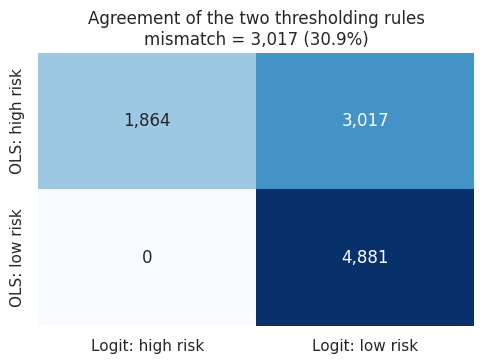

In [10]:
n_test = len(yte)
cm = pd.crosstab(flag_A.map({0:"OLS: low risk",1:"OLS: high risk"}), flag_B.map({0:"Logit: low risk",1:"Logit: high risk"}))
cm_pct = (cm / n_test * 100).round(2)
print("Confusion matrix – counts (rows = OLS+median rule, cols = Logit@0.5):"); display(cm)
print("Same, as % of test set:"); display(cm_pct)

mism = flag_A != flag_B
n_mis = int(mism.sum()); pct_mis = n_mis / n_test * 100
n_A1_B0 = int(((flag_A==1)&(flag_B==0)).sum()); n_A0_B1 = int(((flag_A==0)&(flag_B==1)).sum())
print(f"\nMismatched individuals: {n_mis:,} of {n_test:,} = {pct_mis:.2f}%")
print(f"   flagged high by OLS only  : {n_A1_B0:,}\n   flagged high by Logit only: {n_A0_B1:,}")

fig, ax = plt.subplots(figsize=(5, 3.8))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax); ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title(f"Agreement of the two thresholding rules\nmismatch = {n_mis:,} ({pct_mis:.1f}%)")
plt.tight_layout(); save_fig("03_part1_confusion"); plt.show()
save_table(cm, "part1_confusion_counts")

In [11]:
# ---- Why do they differ?  diagnostics ----
q_B = flag_B.mean()
thr_matched = float(pA.quantile(1 - q_B))                     # OLS cut-off that flags the same share as the logit model
flag_A_matched = (pA >= thr_matched).astype(int); flag_A_05 = (pA >= 0.5).astype(int)
diag = pd.DataFrame({
    "share flagged high (%)": [flag_A.mean()*100, flag_B.mean()*100, flag_A_05.mean()*100, flag_A_matched.mean()*100],
    "accuracy vs truth":      [accuracy_score(yte, flag_A), accuracy_score(yte, flag_B), accuracy_score(yte, flag_A_05), accuracy_score(yte, flag_A_matched)],
    "threshold used":         [median_A, 0.5, 0.5, thr_matched],
    "mismatch with Logit@0.5 (%)": [(flag_A!=flag_B).mean()*100, 0.0, (flag_A_05!=flag_B).mean()*100, (flag_A_matched!=flag_B).mean()*100]},
    index=["OLS @ median", "Logit @ 0.5", "OLS @ 0.5", "OLS @ rate-matched cut-off"]).round(4)
display(diag)

rho = stats.spearmanr(pA, pB).correlation
oob = ((pA < 0) | (pA > 1)).mean() * 100
auc_A, auc_B = roc_auc_score(yte, pA), roc_auc_score(yte, pB)
print(f"Median of OLS predictions          : {median_A:.4f}  (logit threshold = 0.5, true positive rate = {yte.mean():.4f})")
print(f"Share of OLS predictions >= 0.5    : {(pA>=0.5).mean()*100:.2f}%   vs Logit flagged: {flag_B.mean()*100:.2f}%")
print(f"OLS predictions outside [0,1]      : {oob:.2f}%  (min={pA.min():.3f}, max={pA.max():.3f})")
print(f"Spearman rank corr(OLS, Logit)     : {rho:.4f}   -> the two models rank people almost identically")
print(f"AUC  OLS = {auc_A:.4f} | Logit = {auc_B:.4f}")

mm = pd.DataFrame({"n":[n_A1_B0, n_A0_B1],
                   "actual >50K rate (%)":[yte[(flag_A==1)&(flag_B==0)].mean()*100, yte[(flag_A==0)&(flag_B==1)].mean()*100]},
                  index=["OLS high / Logit low", "OLS low / Logit high"]).round(2)
display(mm)
save_table(diag, "part1_diagnostics")
RESULTS["q1"] = dict(n_test=n_test, median_ols=median_A, n_mismatch=n_mis, pct_mismatch=pct_mis, n_ols_only=n_A1_B0, n_logit_only=n_A0_B1,
    flag_rate_ols=float(flag_A.mean()), flag_rate_logit=float(flag_B.mean()), base_rate_test=float(yte.mean()),
    share_ols_ge_05=float((pA>=0.5).mean()), spearman=float(rho), pct_oob=float(oob), auc_ols=float(auc_A), auc_logit=float(auc_B),
    acc_ols=float(accuracy_score(yte, flag_A)), acc_logit=float(accuracy_score(yte, flag_B)),
    mismatch_ols05_pct=float((flag_A_05!=flag_B).mean()*100), mismatch_matched_pct=float((flag_A_matched!=flag_B).mean()*100),
    thr_matched=thr_matched, rate_ols_only_actual=float(mm.iloc[0,1]), rate_logit_only_actual=float(mm.iloc[1,1]))

,share flagged high (%),accuracy vs truth,threshold used,mismatch with Logit@0.5 (%)
OLS @ median,50.0000,0.7141,0.2271,30.9056
Logit @ 0.5,19.0944,0.8472,0.5000,0.0000
OLS @ 0.5,16.8920,0.8452,0.5000,3.2063
OLS @ rate-matched cut-off,19.0944,0.8459,0.4760,2.6839


Median of OLS predictions          : 0.2271  (logit threshold = 0.5, true positive rate = 0.2375)
Share of OLS predictions >= 0.5    : 16.89%   vs Logit flagged: 19.09%
OLS predictions outside [0,1]      : 22.26%  (min=-0.365, max=1.108)
Spearman rank corr(OLS, Logit)     : 0.9855   -> the two models rank people almost identically
AUC  OLS = 0.8961 | Logit = 0.9004


,n,actual >50K rate (%)
OLS high / Logit low,3017,28.47
OLS low / Logit high,0,NaN


**Why the two rules disagree (read the numbers above).**
1. **Different cut-offs, not different rankings.** Thresholding at the *median* forces exactly 50 % of people to be "high risk" no matter what the base rate is, whereas the logistic 0.5 rule flags only people whose estimated probability is at least 50 %. When the positive class is a minority (~24 %), the OLS median is far below 0.5, so many people fall in the "OLS high / Logit low" cell.
2. **Rankings are nearly identical** (Spearman ≈ 0.9+ and similar AUC): re-cutting the OLS score so that it flags the same share as the logit model collapses most of the mismatch (see the rate-matched row).
3. **Different functional form:** OLS is linear in the probability and can produce values < 0 or > 1; logistic is linear in the log-odds and saturates smoothly. They differ mostly in the tails.
4. **Different loss functions:** least squares minimises squared error of a 0/1 target, MLE maximises the Bernoulli likelihood.

---
# Part 2 – The Trap
## 2.1 Simpson's-paradox hunt
**Method.** Rather than guessing one split, we *search*: for 8 demographic/social splits and every predictor we fit a logistic regression on (1) the full data, (2) subgroup A, (3) subgroup B – always **without the splitting variable's own columns**, so the full-data coefficient is the *pooled* trend that ignores the grouping. A predictor is flagged as a **reversal** when a subgroup coefficient is significant (p<0.05) and has the *opposite sign* to the pooled one. We also test whether the two subgroup coefficients differ (z-test on the difference) and apply a Bonferroni correction for the number of comparisons.

In [12]:
med_age = df.age.median()
SPLITS = {
 "Marital status: Married vs Not married": dict(mask=df.marital_grp.eq("Married"), drop=[c for c in X.columns if c.startswith("marital_")], A="Married", B="Not married"),
 "Sex: Male vs Female":                    dict(mask=df.sex.eq("Male"), drop=["sex_Male"], A="Male", B="Female"),
 f"Age: >= {med_age:.0f} (median) vs younger": dict(mask=df.age.ge(med_age), drop=["age"], A="Older", B="Younger"),
 "Race: White vs non-White":               dict(mask=df.race_grp.eq("White"), drop=[c for c in X.columns if c.startswith("race_")], A="White", B="Non-White"),
 "Native country: US vs Non-US":           dict(mask=df.native_grp.eq("US"), drop=[c for c in X.columns if c.startswith("native_")], A="US", B="Non-US/Unknown"),
 "Education: College+ (>=13 yrs) vs less": dict(mask=df.education_num.ge(13), drop=["education_num"], A="College+", B="Less"),
 "Workclass: Private vs other":            dict(mask=df.workclass_grp.eq("Private"), drop=[c for c in X.columns if c.startswith("work_")], A="Private", B="Other"),
 "Hours: >40/wk vs <=40/wk":               dict(mask=df.hours_per_week.gt(40), drop=["hours_per_week"], A=">40 h", B="<=40 h"),
}
def fit_logit(Xd, yd):
    keep = Xd.columns[Xd.std() > 0]
    try:
        m = sm.Logit(yd, sm.add_constant(Xd[keep], has_constant="add")).fit(disp=0, maxiter=300)
        return m if m.mle_retvals.get("converged", True) else None
    except Exception:
        return None

hunt_rows, hunt_models = [], {}
for sname, sp in SPLITS.items():
    mask, cols = sp["mask"], [c for c in X.columns if c not in sp["drop"]]
    mf, mA, mB = fit_logit(Xall_s[cols], y), fit_logit(Xall_s.loc[mask, cols], y[mask]), fit_logit(Xall_s.loc[~mask, cols], y[~mask])
    if any(m is None for m in (mf, mA, mB)):
        print(f"  (skipped '{sname}': a logit fit failed to converge)"); continue
    hunt_models[sname] = (mf, mA, mB)
    for c in cols:
        if not all(c in m.params.index for m in (mf, mA, mB)): continue
        if max(mf.bse[c], mA.bse[c], mB.bse[c]) > 2: continue                    # unstable / near-separation
        bf, bA, bB = mf.params[c], mA.params[c], mB.params[c]
        z = (bA - bB) / np.sqrt(mA.bse[c]**2 + mB.bse[c]**2)
        rev = ((np.sign(bA) != np.sign(bf)) and mA.pvalues[c] < ALPHA) or ((np.sign(bB) != np.sign(bf)) and mB.pvalues[c] < ALPHA)
        hunt_rows.append(dict(split=sname, predictor=c, b_full=bf, b_A=bA, b_B=bB, p_full=mf.pvalues[c], p_A=mA.pvalues[c], p_B=mB.pvalues[c],
                              z_diff=z, p_diff=2*stats.norm.sf(abs(z)), reversal=rev, nA=int(mask.sum()), nB=int((~mask).sum())))
hunt = pd.DataFrame(hunt_rows)
BONF = ALPHA / len(hunt)
print(f"{len(hunt)} (split x predictor) comparisons; Bonferroni alpha = {BONF:.2e}")
print("\nSign reversals (subgroup significant & opposite to pooled sign):")
display(hunt[hunt.reversal].sort_values("z_diff", key=abs, ascending=False).head(10).round(4))
print("Largest differences between subgroup coefficients (reversal or not):")
display(hunt.reindex(hunt.z_diff.abs().sort_values(ascending=False).index).head(10).round(4))
save_table(hunt.round(5), "part2_1_hunt")

202 (split x predictor) comparisons; Bonferroni alpha = 2.48e-04

Sign reversals (subgroup significant & opposite to pooled sign):


,split,predictor,b_full,b_A,b_B,p_full,p_A,p_B,z_diff,p_diff,reversal,nA,nB
21,Marital status: Married vs Not married,sex_Male,1.1539,-0.3365,0.7572,0.0000,0.0000,0.0000,-10.4517,0.000,True,14993,17544
56,Age: >= 37 (median) vs younger,work_Self-employed,-0.0816,-0.3292,0.2498,0.1101,0.0000,0.0156,-4.8538,0.000,True,16729,15808
130,Education: College+ (>=13 yrs) vs less,work_Government,0.0616,-0.2803,0.1961,0.2187,0.0003,0.0042,-4.6232,0.000,True,8064,24473
7,Marital status: Married vs Not married,occ_Craft-repair,0.1121,-0.1812,0.6701,0.1125,0.0380,0.0002,-4.2265,0.000,True,14993,17544
55,Age: >= 37 (median) vs younger,work_Government,0.0014,-0.0403,-0.2909,0.9790,0.5053,0.0054,2.0748,0.038,True,16729,15808


Largest differences between subgroup coefficients (reversal or not):


,split,predictor,b_full,b_A,b_B,p_full,p_A,p_B,z_diff,p_diff,reversal,nA,nB
21,Marital status: Married vs Not married,sex_Male,1.1539,-0.3365,0.7572,0.0000,0.0000,0.0000,-10.4517,0.0,True,14993,17544
3,Marital status: Married vs Not married,capital_gain_log,0.5049,0.4195,0.7036,0.0000,0.0000,0.0000,-8.5430,0.0,False,14993,17544
182,Hours: >40/wk vs <=40/wk,marital_Married,2.5851,2.0049,3.0217,0.0000,0.0000,0.0000,-8.4782,0.0,False,9576,22961
32,Sex: Male vs Female,marital_Married,2.6004,2.2747,3.4211,0.0000,0.0000,0.0000,-8.4174,0.0,False,21775,10762
0,Marital status: Married vs Not married,age,0.5738,0.3283,0.6703,0.0000,0.0000,0.0000,-7.4610,0.0,False,14993,17544
57,Age: >= 37 (median) vs younger,marital_Married,2.8018,2.1321,2.8344,0.0000,0.0000,0.0000,-5.8530,0.0,False,16729,15808
56,Age: >= 37 (median) vs younger,work_Self-employed,-0.0816,-0.3292,0.2498,0.1101,0.0000,0.0156,-4.8538,0.0,True,16729,15808
130,Education: College+ (>=13 yrs) vs less,work_Government,0.0616,-0.2803,0.1961,0.2187,0.0003,0.0042,-4.6232,0.0,True,8064,24473
152,Workclass: Private vs other,age,0.3506,0.4445,0.2479,0.0000,0.0000,0.0000,4.5744,0.0,False,22673,9864
198,Hours: >40/wk vs <=40/wk,sex_Male,0.3149,0.5086,0.0363,0.0000,0.0000,0.5579,4.4639,0.0,False,9576,22961


Selected: split = 'Marital status: Married vs Not married'   key predictor = 'sex_Male'   reversal = True

Logistic coefficient of 'sex_Male' (log-odds), 95% CI:


,n,coef,se,CI_low,CI_high,p_value,odds_ratio
model,,,,,,,
Full dataset (pooled),32537,1.1539,0.0420,1.0715,1.2362,0.0,3.1704
Subgroup A: Married,14993,-0.3365,0.0667,-0.4673,-0.2058,0.0,0.7142
Subgroup B: Not married,17544,0.7572,0.0806,0.5992,0.9153,0.0,2.1324


Other predictors across the three fits:


coef  CI_low  CI_high  p_value
predictor        model                                           
age              Full            0.5738  0.5388   0.6089      0.0
                 A: Married      0.3283  0.2812   0.3753      0.0
                 B: Not married  0.6703  0.5937   0.7468      0.0
education_num    Full            0.6606  0.6195   0.7017      0.0
                 A: Married      0.7014  0.6517   0.7512      0.0
                 B: Not married  0.8025  0.7030   0.9019      0.0
hours_per_week   Full            0.3860  0.3516   0.4203      0.0
                 A: Married      0.3404  0.2969   0.3839      0.0
                 B: Not married  0.5087  0.4352   0.5823      0.0
capital_gain_log Full            0.5049  0.4763   0.5336      0.0
                 A: Married      0.4195  0.3832   0.4558      0.0
                 B: Not married  0.7036  0.6494   0.7577      0.0

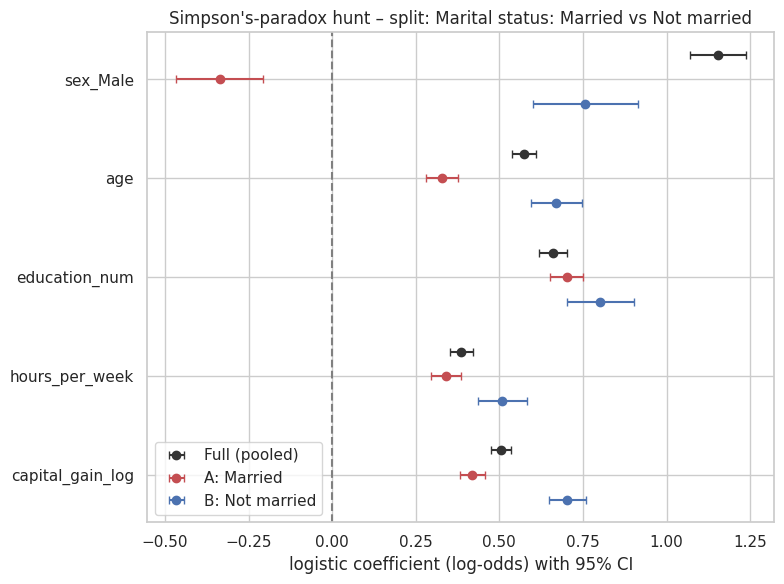

Model-free view – P(income>50K) by 'sex_Male':


,rate | key=1 (%),rate | key=0 (%),n key=1,n key=0,gap (pp)
All,30.59,10.96,21775.0,10762.0,19.63
Married,44.59,45.48,13322.0,1671.0,-0.89
Not married,8.52,4.61,8453.0,9091.0,3.91


In [13]:
SIMPSON_OVERRIDE = None     # e.g. ("Sex: Male vs Female", "marital_Married") to force a specific pair

if SIMPSON_OVERRIDE:
    ch = hunt[(hunt.split == SIMPSON_OVERRIDE[0]) & (hunt.predictor == SIMPSON_OVERRIDE[1])].iloc[0]
else:
    cands = hunt[hunt.reversal & (hunt.p_full < ALPHA) & (hunt.p_diff < BONF)]
    pool = cands if len(cands) else hunt
    ch = pool.reindex(pool.z_diff.abs().sort_values(ascending=False).index).iloc[0]
S_NAME, KEY = ch["split"], ch["predictor"]; SP = SPLITS[S_NAME]
mf, mA, mB = hunt_models[S_NAME]
print(f"Selected: split = '{S_NAME}'   key predictor = '{KEY}'   reversal = {bool(ch.reversal)}")

def coef_row(m, c, label):
    ci = m.conf_int().loc[c]
    return dict(model=label, n=int(m.nobs), coef=m.params[c], se=m.bse[c], CI_low=ci[0], CI_high=ci[1], p_value=m.pvalues[c], odds_ratio=np.exp(m.params[c]))
key_tbl = pd.DataFrame([coef_row(mf, KEY, "Full dataset (pooled)"), coef_row(mA, KEY, f"Subgroup A: {SP['A']}"), coef_row(mB, KEY, f"Subgroup B: {SP['B']}")]).set_index("model")
print(f"\nLogistic coefficient of '{KEY}' (log-odds), 95% CI:"); display(key_tbl.round(4)); save_table(key_tbl.round(5), "part2_1_key_predictor")

others = [c for c in ["age","education_num","hours_per_week","capital_gain_log"] if c != KEY and c in mf.params.index]
oth_tbl = pd.DataFrame([coef_row(m, c, lab) | {"predictor": c} for c in others for m, lab in ((mf,"Full"),(mA,f"A: {SP['A']}"),(mB,f"B: {SP['B']}"))]).set_index(["predictor","model"])
print("Other predictors across the three fits:"); display(oth_tbl[["coef","CI_low","CI_high","p_value"]].round(4)); save_table(oth_tbl.round(5), "part2_1_other_predictors")

# forest plot
plot_preds = [KEY] + others
fig, ax = plt.subplots(figsize=(8, 0.9*len(plot_preds)+1.5)); colors = ["#333333", "#C44E52", "#4C72B0"]
for i, c in enumerate(plot_preds):
    for j, (m, lab) in enumerate(((mf,"Full (pooled)"),(mA,f"A: {SP['A']}"),(mB,f"B: {SP['B']}"))):
        ci = m.conf_int().loc[c]; yy = i + (j-1)*0.25
        ax.errorbar(m.params[c], yy, xerr=[[m.params[c]-ci[0]], [ci[1]-m.params[c]]], fmt="o", color=colors[j], capsize=3, label=lab if i == 0 else None)
ax.axvline(0, color="grey", ls="--"); ax.set_yticks(range(len(plot_preds))); ax.set_yticklabels(plot_preds); ax.invert_yaxis()
ax.set_xlabel("logistic coefficient (log-odds) with 95% CI"); ax.set_title(f"Simpson's-paradox hunt – split: {S_NAME}"); ax.legend(loc="best")
plt.tight_layout(); save_fig("04_simpson_forest"); plt.show()

# raw (model-free) rates for binary key predictors
raw_tbl = None
if X[KEY].isin([0, 1]).all():
    def rate(mask):
        return pd.Series({"rate | key=1 (%)": y[mask & (X[KEY]==1)].mean()*100, "rate | key=0 (%)": y[mask & (X[KEY]==0)].mean()*100,
                          "n key=1": int((mask & (X[KEY]==1)).sum()), "n key=0": int((mask & (X[KEY]==0)).sum())})
    allm = pd.Series(True, index=X.index)
    raw_tbl = pd.DataFrame({"All": rate(allm), SP["A"]: rate(SP["mask"]), SP["B"]: rate(~SP["mask"])}).T.round(2)
    raw_tbl["gap (pp)"] = raw_tbl["rate | key=1 (%)"] - raw_tbl["rate | key=0 (%)"]
    print(f"Model-free view – P(income>50K) by '{KEY}':"); display(raw_tbl); save_table(raw_tbl, "part2_1_raw_rates")

sig_full = key_tbl.p_value.iloc[0] < ALPHA
RESULTS["q2"] = dict(split=S_NAME, key=KEY, reversal=bool(ch.reversal), n_tests=len(hunt), bonferroni=BONF,
    full=key_tbl.iloc[0].to_dict(), A=key_tbl.iloc[1].to_dict(), B=key_tbl.iloc[2].to_dict(), z_diff=float(ch.z_diff), p_diff=float(ch.p_diff),
    labelA=SP["A"], labelB=SP["B"], raw=None if raw_tbl is None else raw_tbl.to_dict())

**Interpretation guide.** The pooled coefficient mixes two things: the *direct* association of the predictor with income and the association it inherits from the grouping variable (which is correlated with both the predictor and income). Once the data are split, that inherited part disappears and the within-group coefficient can shrink or flip. A policy read from the pooled coefficient alone would therefore describe a population-level correlation that is *not* what happens inside each group. Use the CIs above: if the subgroup CIs exclude 0 on opposite sides (or exclude the pooled value), the difference is statistically reliable.

---
## 2.2 Omitted-variable bias
We deliberately drop a likely confounder and refit the logistic model on the training set. **Marital status** is the natural candidate: it is correlated with age (older people are more often married), with sex (about 89 % of the married adults in this sample are men), with hours worked and with income itself (married adults have far higher odds of >50K (odds ratio ≈ 12 in the full model)). Below, a *screening table* shows that this choice is (near-)maximal among the candidates we tried.

In [14]:
DROP_GROUP = "marital"                       # <- prefix of the column group to drop
GROUPS = {"marital": [c for c in X.columns if c.startswith("marital_")], "education_num": ["education_num"], "hours_per_week": ["hours_per_week"],
          "age": ["age"], "occupation": [c for c in X.columns if c.startswith("occ_")], "workclass": [c for c in X.columns if c.startswith("work_")],
          "sex": ["sex_Male"], "race": [c for c in X.columns if c.startswith("race_")], "native": [c for c in X.columns if c.startswith("native_")],
          "capital_gain_log": ["capital_gain_log"], "job_info_missing": ["job_info_missing"]}
KEY_SET = ["age","education_num","hours_per_week","capital_gain_log","capital_loss_log","sex_Male"]

def pct_change(full, red): return 100 * (red - full) / np.abs(full)
scr = []
for g, cols in GROUPS.items():
    m = sm.Logit(ytr, Xtr_c.drop(columns=cols)).fit(disp=0, maxiter=300)
    ks = [k for k in KEY_SET if k not in cols]
    pc = pct_change(logit.params[ks], m.params[ks])
    scr.append(dict(dropped=g, mean_abs_pct_change=pc.abs().mean(), max_abs_pct_change=pc.abs().max(), most_shifted=pc.abs().idxmax()))
scr = pd.DataFrame(scr).set_index("dropped").sort_values("mean_abs_pct_change", ascending=False).round(1)
print("Screening: what happens to the other key coefficients when each variable group is dropped?"); display(scr); save_table(scr, "part2_2_screening")

Screening: what happens to the other key coefficients when each variable group is dropped?


,mean_abs_pct_change,max_abs_pct_change,most_shifted
dropped,,,
marital,101.5,538.4,sex_Male
hours_per_week,17.8,69.0,sex_Male
education_num,12.2,31.3,sex_Male
age,12.0,38.2,sex_Male
occupation,10.8,29.2,education_num
capital_gain_log,7.3,20.1,capital_loss_log
job_info_missing,4.2,15.6,sex_Male
workclass,1.5,4.0,age
sex,0.9,2.5,hours_per_week


Dropped variable group: 'marital'  ->  ['marital_Married', 'marital_Previously-married']
Coefficients before/after (key predictors):


,coef_full,coef_reduced,abs_change,pct_shift,sign_flip,p_full,p_reduced
age,0.3805,0.5855,0.2050,53.8759,False,0.0000,0.0
education_num,0.7203,0.6554,-0.0649,-9.0062,False,0.0000,0.0
hours_per_week,0.3488,0.3682,0.0194,5.5719,False,0.0000,0.0
capital_gain_log,0.5146,0.5052,-0.0094,-1.8237,False,0.0000,0.0
sex_Male,0.1759,1.1232,0.9472,538.3849,False,0.0028,0.0
race_Black,-0.1008,-0.3527,-0.2519,-249.8729,False,0.2298,0.0


All predictors, sorted by |% change|:


,coef_full,coef_reduced,abs_change,pct_shift,sign_flip,p_full,p_reduced
occ_Craft-repair,-0.024,0.146,0.169,719.583,True,0.795,0.085
sex_Male,0.176,1.123,0.947,538.385,False,0.003,0.000
race_Black,-0.101,-0.353,-0.252,-249.873,False,0.230,0.000
occ_Transport-moving,-0.252,-0.089,0.163,64.863,False,0.027,0.414
work_Self-employed,-0.222,-0.100,0.122,54.936,False,0.000,0.084
native_Non-US,-0.156,-0.072,0.085,54.160,False,0.078,0.385
age,0.381,0.586,0.205,53.876,False,0.000,0.000
race_Asian-Pac-Islander,-0.115,-0.055,0.060,52.216,False,0.370,0.639
occ_Machine-op-inspct,-0.431,-0.212,0.220,50.919,False,0.000,0.059
work_Government,-0.137,-0.079,0.058,42.429,False,0.028,0.170



Largest % shift (|full coef|>=0.10): sex_Male (+538.4%)   | largest absolute shift: sex_Male (+0.947 log-odds)

Predictive performance on the test set (compare with the coefficient shifts above):


,AUC,accuracy@0.5
Full model,0.9004,0.8472
Reduced model,0.8581,0.8273


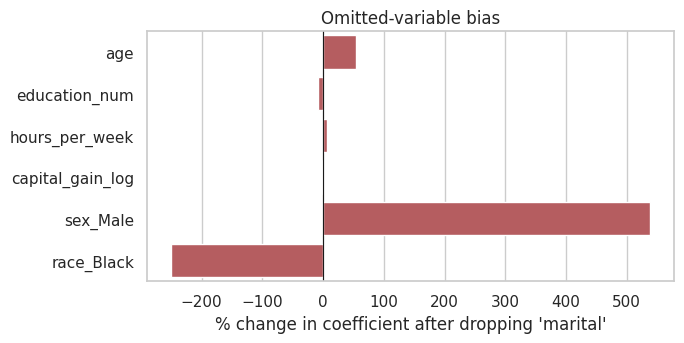

In [15]:
drop_cols = GROUPS[DROP_GROUP]
logit_red = sm.Logit(ytr, Xtr_c.drop(columns=drop_cols)).fit(disp=0, maxiter=300)
common = [c for c in logit.params.index if c not in drop_cols and c != "const"]

ovb = pd.DataFrame({"coef_full": logit.params[common], "coef_reduced": logit_red.params[common]})
ovb["abs_change"] = ovb.coef_reduced - ovb.coef_full
ovb["pct_shift"] = pct_change(ovb.coef_full, ovb.coef_reduced)
ovb["sign_flip"] = np.sign(ovb.coef_full) != np.sign(ovb.coef_reduced)
ovb["p_full"] = logit.pvalues[common]; ovb["p_reduced"] = logit_red.pvalues[common]
save_table(ovb.round(5), "part2_2_ovb_all")

report_preds = [c for c in ["age","education_num","hours_per_week","capital_gain_log","sex_Male","race_Black"] if c in common]
print(f"Dropped variable group: '{DROP_GROUP}'  ->  {drop_cols}")
print("Coefficients before/after (key predictors):"); display(ovb.loc[report_preds].round(4))
print("All predictors, sorted by |% change|:"); display(ovb.reindex(ovb.pct_shift.abs().sort_values(ascending=False).index).round(3).head(12))

big = ovb[ovb.coef_full.abs() >= 0.10]           # ignore near-zero coefficients where % change is unstable
most_pct = big.pct_shift.abs().idxmax(); most_abs = ovb.abs_change.abs().idxmax()
print(f"\nLargest % shift (|full coef|>=0.10): {most_pct} ({ovb.loc[most_pct,'pct_shift']:+.1f}%)   | largest absolute shift: {most_abs} ({ovb.loc[most_abs,'abs_change']:+.3f} log-odds)")

pF, pR = logit.predict(Xte_c), logit_red.predict(Xte_c.drop(columns=drop_cols))
perf = pd.DataFrame({"AUC":[roc_auc_score(yte,pF), roc_auc_score(yte,pR)], "accuracy@0.5":[accuracy_score(yte,pF>=.5), accuracy_score(yte,pR>=.5)]}, index=["Full model","Reduced model"]).round(4)
print("\nPredictive performance on the test set (compare with the coefficient shifts above):"); display(perf)

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.barplot(x=ovb.loc[report_preds,"pct_shift"].values, y=report_preds, color="#C44E52", ax=ax); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel(f"% change in coefficient after dropping '{DROP_GROUP}'"); ax.set_title("Omitted-variable bias")
plt.tight_layout(); save_fig("05_ovb_pct_change"); plt.show()
RESULTS["q3"] = dict(dropped=DROP_GROUP, dropped_cols=drop_cols, table=ovb.loc[report_preds].round(4).to_dict("index"), most_pct=most_pct, most_pct_val=float(ovb.loc[most_pct,"pct_shift"]),
                     most_abs=most_abs, most_abs_val=float(ovb.loc[most_abs,"abs_change"]), auc_full=float(perf.iloc[0,0]), auc_red=float(perf.iloc[1,0]),
                     acc_full=float(perf.iloc[0,1]), acc_red=float(perf.iloc[1,1]), n_flips=int(ovb.sign_flip.sum()))

In [16]:
# ---- Why did they move?  Omitted-variable-bias formula:  bias_j ≈ Σ_c  beta_c * delta_(c->j)
kept = [c for c in Xtr_s.columns if c not in drop_cols]
bias = pd.Series(0.0, index=kept)
for c in drop_cols:
    aux = sm.OLS(Xtr_s[c], sm.add_constant(Xtr_s[kept])).fit()             # regress omitted dummy on the kept predictors
    bias += logit.params[c] * aux.params[kept]
mech = pd.DataFrame({"coef_full": logit.params[KEY_SET], "coef_reduced": logit_red.params[KEY_SET]})
mech["observed_change"] = mech.coef_reduced - mech.coef_full
mech["approx_bias_beta*delta"] = bias[KEY_SET]
print("Approximate OVB (beta_omitted x auxiliary-regression slope) vs observed change (log-odds; approximate for logit):"); display(mech.round(3))
print("Coefficients of the omitted dummies in the full model:", logit.params[drop_cols].round(3).to_dict())

Approximate OVB (beta_omitted x auxiliary-regression slope) vs observed change (log-odds; approximate for logit):


,coef_full,coef_reduced,observed_change,approx_bias_beta*delta
age,0.381,0.586,0.205,0.356
education_num,0.720,0.655,-0.065,0.026
hours_per_week,0.349,0.368,0.019,0.097
capital_gain_log,0.515,0.505,-0.009,0.072
capital_loss_log,0.242,0.241,-0.001,0.043
sex_Male,0.176,1.123,0.947,0.800


Coefficients of the omitted dummies in the full model: {'marital_Married': 2.517, 'marital_Previously-married': 0.409}


### 2.2b – How would you *detect* a confound you cannot see? (demonstration for Part 3 Q4)
A concrete, practical method is a **residual audit against candidate variables that are not in the model**: compute residuals, group them by each candidate variable (including ones you excluded or never collected proxies for) and test whether the mean residual differs by group (one-way ANOVA; η² = share of residual variance explained). A model that has captured everything should leave residuals unrelated to any candidate. Below, the audit is run on the *reduced* model (where we know the culprit) and on the *full* model (where the real audit would happen).

In [17]:
def residual_audit(p, y_true, cols):
    r = ((y_true - p) / np.sqrt(p * (1 - p))).astype(float)                 # Pearson residuals
    fr = df.loc[r.index]; rows = []
    for c in cols:
        g = fr[c]
        if pd.api.types.is_numeric_dtype(g) and g.nunique() > 12: g = pd.qcut(g, 10, duplicates="drop")
        g = g.astype(object).where(g.notna(), "Missing").astype(str)
        groups = [r[g == k].values for k in g.unique() if (g == k).sum() > 1]
        F, pv = stats.f_oneway(*groups)
        ssb = sum(len(a) * (a.mean() - r.mean())**2 for a in groups); sst = ((r - r.mean())**2).sum()
        rows.append(dict(candidate=c, F=F, p_value=pv, eta_squared=ssb/sst))
    return pd.DataFrame(rows).set_index("candidate").sort_values("eta_squared", ascending=False)

AUDIT_COLS = ["marital_status", "relationship", "education", "occupation", "workclass", "native_country", "race", "fnlwgt"]
aud_red, aud_full = residual_audit(pR, yte, AUDIT_COLS), residual_audit(pF, yte, AUDIT_COLS)
print("Residual audit – REDUCED model (marital info removed):"); display(aud_red.round(5))
print("Residual audit – FULL model:"); display(aud_full.round(5))
print("Mean Pearson residual by raw marital_status in the reduced model (systematic pattern = red flag):")
r_red = (yte - pR) / np.sqrt(pR * (1 - pR)); display(r_red.groupby(df.loc[r_red.index, "marital_status"]).agg(["mean","count"]).round(3))
save_table(aud_red.round(6), "part2_2b_audit_reduced"); save_table(aud_full.round(6), "part2_2b_audit_full")
RESULTS["q4"] = dict(audit_reduced_top=aud_red.index[0], eta_red=float(aud_red.eta_squared.iloc[0]), p_red=float(aud_red.p_value.iloc[0]),
                     audit_full_top=aud_full.index[0], eta_full=float(aud_full.eta_squared.iloc[0]), p_full=float(aud_full.p_value.iloc[0]),
                     eta_red_marital=float(aud_red.loc["marital_status","eta_squared"]), p_red_marital=float(aud_red.loc["marital_status","p_value"]),
                     eta_full_marital=float(aud_full.loc["marital_status","eta_squared"]), p_full_marital=float(aud_full.loc["marital_status","p_value"]))

Residual audit – REDUCED model (marital info removed):


,F,p_value,eta_squared
candidate,,,
relationship,255.48863,0.00000,0.11578
marital_status,134.63332,0.00000,0.07648
native_country,1.29821,0.09858,0.00531
workclass,6.24614,0.00000,0.00383
education,0.79595,0.68357,0.00122
fnlwgt,1.09169,0.36494,0.00101
occupation,0.52846,0.91818,0.00076
race,0.83453,0.50295,0.00034


Residual audit – FULL model:


,F,p_value,eta_squared
candidate,,,
native_country,2.48010,0.00000,0.01010
relationship,11.24845,0.00000,0.00573
workclass,5.59007,0.00001,0.00343
education,0.71105,0.77582,0.00109
occupation,0.43356,0.96465,0.00062
fnlwgt,0.57528,0.81852,0.00053
marital_status,0.81395,0.55884,0.00050
race,0.94825,0.43480,0.00039


Mean Pearson residual by raw marital_status in the reduced model (systematic pattern = red flag):


,mean,count
marital_status,,
Divorced,-0.264,1350
Married-AF-spouse,1.520,8
Married-civ-spouse,0.275,4443
Married-spouse-absent,-0.232,121
Never-married,-0.257,3220
Separated,-0.221,308
Widowed,-0.241,312


---
## 2.3 Adversarial subset – confident, wrong predictions
On the **test set** of the (full) logistic model we look for
* **confident false positives:** P(y=1) ≥ 0.75 but y = 0, and
* **confident false negatives:** P(y=1) ≤ 0.25 but y = 1,

and draw ≈ 50 of them at random (seed = `RANDOM_STATE`).

Confident wrong predictions on test set: 503 of 9,762 = 5.15%
   confident false positives (P>=0.75, y=0): 116  (1.19%)
   confident false negatives (P<=0.25, y=1): 387  (3.96%)
Sampled 50 rows: 11 FP + 39 FN

Demographics: 50 adversarial rows vs full test set (means for numeric, % for binary):


,adversarial_50,full_test,p_value
feature,,,
age,43.76,38.5988,0.0055
education_num,10.32,10.0562,0.4016
hours_per_week,43.42,40.3341,0.1613
% Male,80.00,66.8408,0.0503
% White,84.00,85.4845,0.6899
% Married,70.00,45.5952,0.0006
% capital_gain > 0,14.00,7.8160,0.1091
% Non-US born,6.00,8.9531,0.6222
% actual income >50K,78.00,23.7451,0.0000


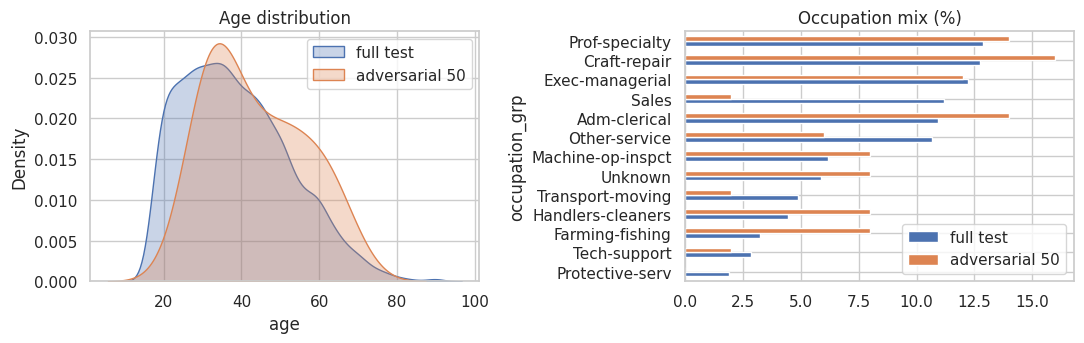

In [18]:
fp_mask = (pB >= 0.75) & (yte == 0); fn_mask = (pB <= 0.25) & (yte == 1)
adv_all = pB.index[fp_mask | fn_mask]
n_adv_all = len(adv_all); n_fp, n_fn = int(fp_mask.sum()), int(fn_mask.sum())
rng = np.random.default_rng(RANDOM_STATE)
adv_idx = pd.Index(rng.choice(adv_all, size=min(50, n_adv_all), replace=False))
print(f"Confident wrong predictions on test set: {n_adv_all} of {len(yte):,} = {n_adv_all/len(yte)*100:.2f}%")
print(f"   confident false positives (P>=0.75, y=0): {n_fp}  ({n_fp/len(yte)*100:.2f}%)")
print(f"   confident false negatives (P<=0.25, y=1): {n_fn}  ({n_fn/len(yte)*100:.2f}%)")
print(f"Sampled {len(adv_idx)} rows: {int(fp_mask[adv_idx].sum())} FP + {int(fn_mask[adv_idx].sum())} FN")

d_adv = df.loc[adv_idx]; d_rest = df_te.drop(index=adv_idx, errors="ignore")
def cmp_num(col):
    t = stats.ttest_ind(d_adv[col], d_rest[col], equal_var=False)
    return dict(feature=col, adversarial_50=d_adv[col].mean(), full_test=df_te[col].mean(), p_value=t.pvalue)
def cmp_bin(name, f):
    a, b = f(d_adv), f(d_rest); tab = [[a.sum(), (~a).sum()], [b.sum(), (~b).sum()]]
    return dict(feature=name, adversarial_50=a.mean()*100, full_test=f(df_te).mean()*100, p_value=stats.fisher_exact(tab)[1])
demo = pd.DataFrame([cmp_num("age"), cmp_num("education_num"), cmp_num("hours_per_week"),
    cmp_bin("% Male", lambda d: d.sex.eq("Male")), cmp_bin("% White", lambda d: d.race_grp.eq("White")), cmp_bin("% Married", lambda d: d.marital_grp.eq("Married")),
    cmp_bin("% capital_gain > 0", lambda d: d.capital_gain.gt(0)), cmp_bin("% Non-US born", lambda d: d.native_grp.eq("Non-US")),
    cmp_bin("% actual income >50K", lambda d: d.income_bin.eq(1))]).set_index("feature").round(4)
print("\nDemographics: 50 adversarial rows vs full test set (means for numeric, % for binary):"); display(demo); save_table(demo, "part2_3_demographics")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.kdeplot(df_te.age, ax=ax[0], label="full test", fill=True, alpha=.3); sns.kdeplot(d_adv.age, ax=ax[0], label="adversarial 50", fill=True, alpha=.3); ax[0].legend(); ax[0].set_title("Age distribution")
occ = pd.DataFrame({"full test": df_te.occupation_grp.value_counts(normalize=True), "adversarial 50": d_adv.occupation_grp.value_counts(normalize=True)}).fillna(0)*100
occ.sort_values("full test").plot.barh(ax=ax[1]); ax[1].set_title("Occupation mix (%)"); plt.tight_layout(); save_fig("06_adversarial_demographics"); plt.show()

In [19]:
# ---- what do these rows have in common?  scan many binary traits, Fisher exact vs the rest of the test set
def trait_frame(d):
    t = pd.DataFrame(index=d.index)
    t["Married"] = d.marital_grp.eq("Married"); t["Never-married"] = d.marital_grp.eq("Never-married"); t["Previously-married"] = d.marital_grp.eq("Previously-married")
    t["Male"] = d.sex.eq("Male"); t["Female"] = d.sex.eq("Female"); t["White"] = d.race_grp.eq("White"); t["Non-US born"] = d.native_grp.eq("Non-US")
    t["Age >= 50"] = d.age.ge(50); t["Age < 30"] = d.age.lt(30); t["Hours >= 50"] = d.hours_per_week.ge(50); t["Hours < 35"] = d.hours_per_week.lt(35)
    t["College+ (edu>=13)"] = d.education_num.ge(13); t["HS or less (edu<=9)"] = d.education_num.le(9)
    t["capital_gain > 0"] = d.capital_gain.gt(0); t["capital_loss > 0"] = d.capital_loss.gt(0)
    for o in ["Exec-managerial","Prof-specialty","Sales","Craft-repair","Adm-clerical","Other-service","Unknown"]: t[f"Occ: {o}"] = d.occupation_grp.eq(o)
    for w in ["Private","Self-employed","Government"]: t[f"Work: {w}"] = d.workclass_grp.eq(w)
    return t
T_te = trait_frame(df_te)
def trait_scan(idx):
    T_s = T_te.loc[idx]; T_r = T_te.drop(index=idx); rows = []
    for c in T_te.columns:
        a, b = T_s[c].sum(), T_r[c].sum()
        rows.append(dict(trait=c, pct_in_subset=T_s[c].mean()*100, pct_in_test=T_te[c].mean()*100, lift=T_s[c].mean()/max(T_te[c].mean(), 1e-9),
                         p_value=stats.fisher_exact([[a, len(T_s)-a], [b, len(T_r)-b]])[1]))
    return pd.DataFrame(rows).set_index("trait").sort_values("p_value")
scan50 = trait_scan(adv_idx); print("Top distinguishing traits of the 50-row sample:"); display(scan50.head(8).round(4))
scan_fn = trait_scan(pB.index[fn_mask]); scan_fp = trait_scan(pB.index[fp_mask])
print(f"All {n_fn} confident FALSE NEGATIVES:"); display(scan_fn.head(5).round(4))
print(f"All {n_fp} confident FALSE POSITIVES:"); display(scan_fp.head(5).round(4))
# also try conjunctions of two traits (Bonferroni-relevant: ~500 pairs) – prevalence must be >= 25% of the 50 rows
import itertools
pair_rows = []
T_s50, T_r50 = T_te.loc[adv_idx], T_te.drop(index=adv_idx)
for c1, c2 in itertools.combinations(T_te.columns, 2):
    a_s, a_r, a_t = (T_s50[c1] & T_s50[c2]), (T_r50[c1] & T_r50[c2]), (T_te[c1] & T_te[c2])
    if a_s.mean() < 0.25: continue
    pair_rows.append(dict(trait=f"{c1} & {c2}", pct_in_subset=a_s.mean()*100, pct_in_test=a_t.mean()*100, lift=a_s.mean()/max(a_t.mean(), 1e-9),
                          p_value=stats.fisher_exact([[a_s.sum(), len(a_s)-a_s.sum()], [a_r.sum(), len(a_r)-a_r.sum()]])[1]))
pairs50 = pd.DataFrame(pair_rows).set_index("trait").sort_values("p_value"); print("Top two-trait conjunctions (>=25% prevalence in the 50 rows):"); display(pairs50.head(5).round(4))
top = scan50[scan50.lift > 1].iloc[0]; top_name = scan50[scan50.lift > 1].index[0]
print(f"\nMost distinctive common trait of the 50 rows: '{top_name}' – {top.pct_in_subset:.0f}% of the subset vs {top.pct_in_test:.0f}% of the test set (Fisher p={top.p_value:.2g})")
save_table(scan50.round(5), "part2_3_trait_scan")

Top distinguishing traits of the 50-row sample:


,pct_in_subset,pct_in_test,lift,p_value
trait,,,,
Never-married,8.0,32.9850,0.2425,0.0001
Married,70.0,45.5952,1.5353,0.0006
Work: Private,46.0,69.2891,0.6639,0.0006
Age < 30,12.0,30.2192,0.3971,0.0048
Work: Government,28.0,13.6550,2.0505,0.0064
Occ: Sales,2.0,11.1657,0.1791,0.0393
Female,20.0,33.1592,0.6032,0.0503
Male,80.0,66.8408,1.1969,0.0503


All 387 confident FALSE NEGATIVES:


,pct_in_subset,pct_in_test,lift,p_value
trait,,,,
Age < 30,16.2791,30.2192,0.5387,0.0000
Hours < 35,8.2687,17.1891,0.4810,0.0000
Occ: Other-service,5.4264,10.6843,0.5079,0.0003
Never-married,25.0646,32.9850,0.7599,0.0006
Hours >= 50,26.0982,19.3505,1.3487,0.0010


All 116 confident FALSE POSITIVES:


,pct_in_subset,pct_in_test,lift,p_value
trait,,,,
Married,98.2759,45.5952,2.1554,0.0
College+ (edu>=13),70.6897,24.5134,2.8837,0.0
capital_gain > 0,41.3793,7.8160,5.2942,0.0
Never-married,1.7241,32.9850,0.0523,0.0
HS or less (edu<=9),9.4828,45.3698,0.2090,0.0


Top two-trait conjunctions (>=25% prevalence in the 50 rows):


,pct_in_subset,pct_in_test,lift,p_value
trait,,,,
Married & Male,60.0,40.8216,1.4698,0.0087
White & Work: Private,40.0,59.0453,0.6774,0.0088
Male & Age >= 50,30.0,15.5398,1.9305,0.0094
Married & White,56.0,40.8318,1.3715,0.0309
Male & Work: Private,32.0,45.5337,0.7028,0.0637



Most distinctive common trait of the 50 rows: 'Married' – 70% of the subset vs 46% of the test set (Fisher p=0.00055)


In [20]:
# ---- Statistical mechanism: is it a missing non-linearity / interaction?  Refit with extra terms and count confident errors again.
def augment(Xs):
    a = Xs.copy()
    a["age_sq"] = Xs.age**2; a["hours_sq"] = Xs.hours_per_week**2; a["edu_x_hours"] = Xs.education_num*Xs.hours_per_week
    a["age_x_married"] = Xs.age*Xs.marital_Married; a["sex_x_married"] = Xs.sex_Male*Xs.marital_Married; a["edu_x_married"] = Xs.education_num*Xs.marital_Married
    return a
Xtr_a, Xte_a = sm.add_constant(augment(Xtr_s), has_constant="add"), sm.add_constant(augment(Xte_s), has_constant="add")
logit_aug = sm.Logit(ytr, Xtr_a).fit(disp=0, maxiter=300); pAug = logit_aug.predict(Xte_a)
conf_err = lambda p: ((p >= .75) & (yte == 0)) | ((p <= .25) & (yte == 1))
lr = 2 * (logit_aug.llf - logit.llf); lr_p = stats.chi2.sf(lr, logit_aug.df_model - logit.df_model)
mech23 = pd.DataFrame({"confident errors (test)": [int(conf_err(pB).sum()), int(conf_err(pAug).sum())],
                       "of the 50 sampled rows still confidently wrong": [int(conf_err(pB)[adv_idx].sum()), int(conf_err(pAug)[adv_idx].sum())],
                       "AUC": [roc_auc_score(yte, pB), roc_auc_score(yte, pAug)]}, index=["Base logit", "Logit + non-linear/interaction terms"]).round(4)
display(mech23); print(f"Likelihood-ratio test of the added terms: chi2={lr:.1f}, p={lr_p:.2g}")
print("New terms (log-odds):"); display(logit_aug.params[[c for c in logit_aug.params.index if c not in logit.params.index]].round(3).to_frame("coef").join(logit_aug.pvalues.rename("p")).round(4))

# average contribution of each feature to the logit score: adversarial rows vs the rest of the test set
contrib = Xte_c * logit.params
cdiff = (contrib.loc[adv_idx].mean() - contrib.drop(index=adv_idx).mean()).drop("const")
print("Features whose logit contribution differs most between the 50 rows and the rest of the test set:")
display(cdiff.reindex(cdiff.abs().sort_values(ascending=False).index).head(6).round(3).to_frame("mean contribution difference (log-odds)"))
print(f"Mean predicted P on the 50 rows: {pB[adv_idx].mean():.3f}   actual positive rate on the 50 rows: {yte[adv_idx].mean():.3f}")

RESULTS["q5"] = dict(n_adv=n_adv_all, pct_adv=n_adv_all/len(yte)*100, n_fp=n_fp, n_fn=n_fn, n_sample=len(adv_idx),
    sample_fp=int(fp_mask[adv_idx].sum()), sample_fn=int(fn_mask[adv_idx].sum()), top_trait=top_name, top_trait_pct=float(top.pct_in_subset), top_trait_test_pct=float(top.pct_in_test),
    top_trait_p=float(top.p_value), pair_trait=pairs50.index[0], pair_pct=float(pairs50.pct_in_subset.iloc[0]), pair_test_pct=float(pairs50.pct_in_test.iloc[0]), pair_p=float(pairs50.p_value.iloc[0]), scan50=scan50.head(5).round(4).to_dict("index"), demo=demo.to_dict("index"),
    conf_err_base=int(conf_err(pB).sum()), conf_err_aug=int(conf_err(pAug).sum()), sample_err_aug=int(conf_err(pAug)[adv_idx].sum()), lr_chi2=float(lr), lr_p=float(lr_p),
    mean_p_sample=float(pB[adv_idx].mean()), actual_rate_sample=float(yte[adv_idx].mean()))

,confident errors (test),of the 50 sampled rows still confidently wrong,AUC
Base logit,503,50,0.9004
Logit + non-linear/interaction terms,445,39,0.9080


Likelihood-ratio test of the added terms: chi2=536.6, p=1.1e-112
New terms (log-odds):


,coef,p
age_sq,-0.372,0.0000
hours_sq,-0.089,0.0000
edu_x_hours,-0.050,0.0304
age_x_married,-0.270,0.0000
sex_x_married,-1.318,0.0000
edu_x_married,-0.159,0.0053


Features whose logit contribution differs most between the 50 rows and the rest of the test set:


,mean contribution difference (log-odds)
marital_Married,0.617
age,0.145
capital_gain_log,0.111
hours_per_week,0.088
education_num,0.075
occ_Farming-fishing,-0.058


Mean predicted P on the 50 rows: 0.302   actual positive rate on the 50 rows: 0.780


---
## 2.4 Fairness trade-off analysis
Sensitive attribute: **sex** (Group A = Female, Group B = Male). Threshold sweep t ∈ {0.05, 0.15, …, 0.95} on the full logistic model's test-set probabilities; ŷ = 1 if P ≥ t.

* **DP** = P(ŷ=1 | A) / P(ŷ=1 | B)
* **EO** = min(TPR_A / TPR_B, FPR_A / FPR_B)
* **PP** = P(y=1 | ŷ=1, A) / P(y=1 | ŷ=1, B)

Ideal value of each = 1.0. A ratio that cannot be computed (0/0 or ÷0) is `NaN`.

In [21]:
SENSITIVE, GROUP_A, GROUP_B = "sex", "Female", "Male"
THRESHOLDS = np.round(np.arange(0.05, 1.0, 0.10), 2)
maskA = (df_te[SENSITIVE] == GROUP_A).values; maskB = (df_te[SENSITIVE] == GROUP_B).values
y_arr, p_arr = yte.values, pB.values

def rates(yh, m):
    yt, yp = y_arr[m], yh[m]
    return dict(sel=yp.mean(), tpr=yp[yt==1].mean() if (yt==1).any() else np.nan, fpr=yp[yt==0].mean() if (yt==0).any() else np.nan,
                ppv=yt[yp==1].mean() if (yp==1).any() else np.nan, n_flag=int(yp.sum()))
def ratio(a, b): return np.nan if (pd.isna(a) or pd.isna(b) or b == 0) else a / b

rows = []
for t in THRESHOLDS:
    yh = (p_arr >= t).astype(int); a, b = rates(yh, maskA), rates(yh, maskB)
    tpr_r, fpr_r = ratio(a["tpr"], b["tpr"]), ratio(a["fpr"], b["fpr"])
    rows.append({"threshold": t, "DP": ratio(a["sel"], b["sel"]), "EO": np.nan if (pd.isna(tpr_r) and pd.isna(fpr_r)) else np.nanmin([tpr_r, fpr_r]), "PP": ratio(a["ppv"], b["ppv"]),
                 "TPR_ratio": tpr_r, "FPR_ratio": fpr_r, "sel_A": a["sel"], "sel_B": b["sel"], "TPR_A": a["tpr"], "TPR_B": b["tpr"], "FPR_A": a["fpr"], "FPR_B": b["fpr"],
                 "PPV_A": a["ppv"], "PPV_B": b["ppv"], "n_flag_A": a["n_flag"], "n_flag_B": b["n_flag"], "accuracy": (yh == y_arr).mean()})
fair = pd.DataFrame(rows).set_index("threshold")
print(f"Group sizes in test set: {GROUP_A} n={maskA.sum():,} (base rate {y_arr[maskA].mean():.3f}) | {GROUP_B} n={maskB.sum():,} (base rate {y_arr[maskB].mean():.3f})")
print("\nTable 2.4 – fairness metrics per threshold"); display(fair[["DP","EO","PP","accuracy"]].round(3)); print("Underlying group rates:"); display(fair.drop(columns=["DP","EO","PP","accuracy"]).round(3))
save_table(fair.round(5), "part2_4_fairness_sweep")

Group sizes in test set: Female n=3,237 (base rate 0.101) | Male n=6,525 (base rate 0.305)

Table 2.4 – fairness metrics per threshold


,DP,EO,PP,accuracy
threshold,,,,
0.05,0.582,0.596,0.549,0.610
0.15,0.331,0.288,0.875,0.756
0.25,0.264,0.218,0.948,0.813
0.35,0.219,0.166,1.011,0.838
0.45,0.197,0.132,1.059,0.847
0.55,0.169,0.087,1.119,0.845
0.65,0.147,0.081,1.076,0.835
0.75,0.111,0.056,1.064,0.817
0.85,0.105,0.072,1.012,0.797


Underlying group rates:


,TPR_ratio,FPR_ratio,sel_A,sel_B,TPR_A,TPR_B,FPR_A,FPR_B,PPV_A,PPV_B,n_flag_A,n_flag_B
threshold,,,,,,,,,,,,
0.05,0.965,0.596,0.418,0.719,0.954,0.988,0.358,0.601,0.230,0.419,1354,4693
0.15,0.876,0.288,0.189,0.572,0.823,0.939,0.118,0.410,0.439,0.501,613,3730
0.25,0.755,0.218,0.120,0.457,0.651,0.863,0.061,0.279,0.546,0.576,390,2981
0.35,0.669,0.166,0.079,0.360,0.505,0.754,0.031,0.186,0.647,0.640,255,2346
0.45,0.631,0.132,0.057,0.290,0.416,0.659,0.017,0.128,0.735,0.694,185,1892
0.55,0.573,0.087,0.039,0.232,0.321,0.561,0.008,0.087,0.827,0.739,127,1511
0.65,0.478,0.081,0.025,0.170,0.211,0.441,0.004,0.051,0.852,0.792,81,1109
0.75,0.356,0.056,0.012,0.111,0.110,0.309,0.001,0.025,0.900,0.846,40,727
0.85,0.320,0.072,0.006,0.062,0.058,0.182,0.001,0.009,0.905,0.894,21,405


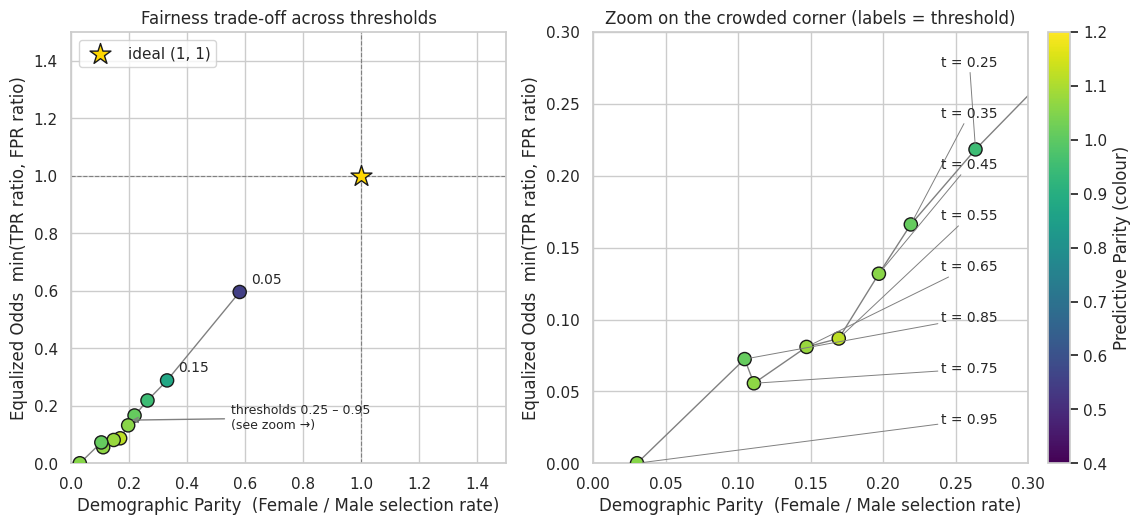

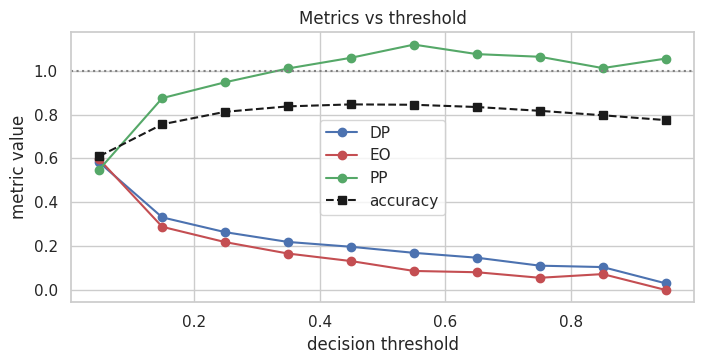

In [22]:
# ---- trade-off chart: X = DP, Y = EO, labelled by threshold  (left = required 0–1.5 axes, right = zoom on the crowded corner)
ok = fair[(fair.DP.between(0, 1.5)) & (fair.EO.between(0, 1.5))]
ZOOM = 0.30
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for k, (ax, lim) in enumerate(zip(axes, [1.5, ZOOM])):
    sc = ax.scatter(ok.DP, ok.EO, c=ok.PP.clip(0, 1.5), cmap="viridis", s=90, edgecolor="k", zorder=3, vmin=0.4, vmax=1.2)
    ax.plot(ok.DP, ok.EO, color="grey", lw=1, zorder=2)
    if k == 0:
        for t, r in ok.iterrows():
            if r.DP > ZOOM: ax.annotate(f"{t:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=(8, 6), fontsize=10)
        ax.annotate("thresholds 0.25 – 0.95\n(see zoom →)", (0.2, 0.15), xytext=(0.55, 0.12), fontsize=9, arrowprops=dict(arrowstyle="->", color="grey"))
        ax.scatter([1], [1], marker="*", s=250, color="gold", edgecolor="k", zorder=4, label="ideal (1, 1)")
        ax.axvline(1, ls="--", color="grey", lw=.8); ax.axhline(1, ls="--", color="grey", lw=.8); ax.legend(loc="upper left")
        ax.set_title("Fairness trade-off across thresholds")
    else:
        zoom_pts = ok[(ok.DP <= lim) & (ok.EO <= lim)].sort_values("EO", ascending=False)
        ys = np.linspace(lim * 0.93, lim * 0.10, len(zoom_pts))
        for (t, r), yl in zip(zoom_pts.iterrows(), ys):
            ax.annotate(f"t = {t:.2f}", (r.DP, r.EO), xytext=(lim * 0.80, yl), fontsize=10, va="center",
                        arrowprops=dict(arrowstyle="-", color="grey", lw=.7, shrinkA=0, shrinkB=4))
        ax.set_title("Zoom on the crowded corner (labels = threshold)")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_xlabel("Demographic Parity  (Female / Male selection rate)"); ax.set_ylabel("Equalized Odds  min(TPR ratio, FPR ratio)")
plt.colorbar(sc, ax=axes, label="Predictive Parity (colour)", fraction=0.03, pad=0.02)
save_fig("07_fairness_tradeoff"); plt.show()
if len(ok) < len(fair): print("Not plotted (NaN or outside 0–1.5):", sorted(set(fair.index) - set(ok.index)))

fig, ax = plt.subplots(figsize=(7.2, 3.8))
for m, col in (("DP","#4C72B0"),("EO","#C44E52"),("PP","#55A868")): ax.plot(fair.index, fair[m], marker="o", label=m, color=col)
ax.plot(fair.index, fair.accuracy, marker="s", ls="--", color="k", label="accuracy"); ax.axhline(1, color="grey", ls=":")
ax.set_xlabel("decision threshold"); ax.set_ylabel("metric value"); ax.set_title("Metrics vs threshold"); ax.legend(); plt.tight_layout(); save_fig("08_metrics_vs_threshold"); plt.show()

In [23]:
# ---- quantify the trade-off.  "closeness" = min(m, 1/m) in [0,1]  (1 = perfectly fair; treats 0.8 and 1.25 the same)
def closeness(m): return np.nan if pd.isna(m) else (0.0 if m <= 0 else min(m, 1 / m))
def tradeoff(m_up, m_down, min_gain=0.01):
    """all ordered threshold pairs (ti -> tj) where m_up gets closer to 1 while m_down gets further from 1"""
    out = []
    for ti in fair.index:
        for tj in fair.index:
            ui, uj, di, dj = fair.loc[ti, m_up], fair.loc[tj, m_up], fair.loc[ti, m_down], fair.loc[tj, m_down]
            cui, cuj, cdi, cdj = map(closeness, (ui, uj, di, dj))
            if any(pd.isna(v) for v in (cui, cuj, cdi, cdj)) or cui == 0 or cdi == 0: continue
            if cuj > cui + min_gain and cdj < cdi - 1e-9:
                gain, loss = (cuj - cui) / cui * 100, (cdi - cdj) / cdi * 100
                out.append(dict(from_t=ti, to_t=tj, up_before=ui, up_after=uj, gain_pct=gain, down_before=di, down_after=dj, loss_pct=loss, cost=loss / gain))
    return pd.DataFrame(out).sort_values("gain_pct", ascending=False) if out else pd.DataFrame()

TRADE = {}
for m_up, m_down in (("DP","EO"), ("EO","DP"), ("PP","DP"), ("PP","EO")):
    tt = tradeoff(m_up, m_down); TRADE[(m_up, m_down)] = tt
    print(f"\n=== Improve {m_up}, sacrifice {m_down} ===")
    if tt.empty: print("  no threshold pair where improving", m_up, "worsens", m_down); continue
    r = tt.iloc[0]
    print(f"  Moving threshold {r.from_t:.2f} -> {r.to_t:.2f} improves {m_up} from {r.up_before:.3f} to {r.up_after:.3f} (a {r.gain_pct:.1f}% gain in closeness to 1), "
          f"while {m_down} drops from {r.down_before:.3f} to {r.down_after:.3f} (a {r.loss_pct:.1f}% loss). Trade-off cost = W/Z = {r.cost:.2f}")
    if len(tt) > 1: display(tt.head(3).round(3))
RESULTS["q6_8"] = {f"{a}_up_{b}_down": (None if tt.empty else tt.iloc[0].round(4).to_dict()) for (a, b), tt in TRADE.items()}

# overall span of the sweep (lowest -> highest threshold with all metrics defined)
valid = fair.dropna(subset=["DP","EO","PP"]); t_lo, t_hi = valid.index.min(), valid.index.max()
best_pp_t = valid.PP.map(closeness).idxmax(); best_acc_t = fair.accuracy.idxmax()
print(f"\nBest PP (closest to 1) at t={best_pp_t:.2f} (PP={fair.loc[best_pp_t,'PP']:.3f}); best DP at t={valid.DP.map(closeness).idxmax():.2f}; best EO at t={valid.EO.map(closeness).idxmax():.2f}; best accuracy at t={best_acc_t:.2f} ({fair.accuracy.max():.3f})")
print("KEY INSIGHT check – is there ONE threshold where all three are near 1?")
fair["min_closeness"] = fair[["DP","EO","PP"]].apply(lambda col: col.map(closeness)).min(axis=1); display(fair[["DP","EO","PP","min_closeness","accuracy"]].round(3))
RESULTS["fair"] = dict(best_pp_t=float(best_pp_t), best_acc_t=float(best_acc_t), best_acc=float(fair.accuracy.max()), base_rate_A=float(y_arr[maskA].mean()), base_rate_B=float(y_arr[maskB].mean()),
                        nA=int(maskA.sum()), nB=int(maskB.sum()), max_min_closeness=float(fair.min_closeness.max()))


=== Improve DP, sacrifice EO ===
  no threshold pair where improving DP worsens EO

=== Improve EO, sacrifice DP ===
  Moving threshold 0.75 -> 0.85 improves EO from 0.056 to 0.072 (a 30.2% gain in closeness to 1), while DP drops from 0.111 to 0.105 (a 5.8% loss). Trade-off cost = W/Z = 0.19

=== Improve PP, sacrifice DP ===
  Moving threshold 0.05 -> 0.35 improves PP from 0.549 to 1.011 (a 80.1% gain in closeness to 1), while DP drops from 0.582 to 0.219 (a 62.3% loss). Trade-off cost = W/Z = 0.78


,from_t,to_t,up_before,up_after,gain_pct,down_before,down_after,loss_pct,cost
2,0.05,0.35,0.549,1.011,80.068,0.582,0.219,62.326,0.778
7,0.05,0.85,0.549,1.012,79.787,0.582,0.105,82.028,1.028
1,0.05,0.25,0.549,0.948,72.462,0.582,0.264,54.654,0.754



=== Improve PP, sacrifice EO ===
  Moving threshold 0.05 -> 0.35 improves PP from 0.549 to 1.011 (a 80.1% gain in closeness to 1), while EO drops from 0.596 to 0.166 (a 72.1% loss). Trade-off cost = W/Z = 0.90


,from_t,to_t,up_before,up_after,gain_pct,down_before,down_after,loss_pct,cost
2,0.05,0.35,0.549,1.011,80.068,0.596,0.166,72.113,0.901
7,0.05,0.85,0.549,1.012,79.787,0.596,0.072,87.836,1.101
1,0.05,0.25,0.549,0.948,72.462,0.596,0.218,63.350,0.874



Best PP (closest to 1) at t=0.35 (PP=1.011); best DP at t=0.05; best EO at t=0.05; best accuracy at t=0.45 (0.847)
KEY INSIGHT check – is there ONE threshold where all three are near 1?


,DP,EO,PP,min_closeness,accuracy
threshold,,,,,
0.05,0.582,0.596,0.549,0.549,0.610
0.15,0.331,0.288,0.875,0.288,0.756
0.25,0.264,0.218,0.948,0.218,0.813
0.35,0.219,0.166,1.011,0.166,0.838
0.45,0.197,0.132,1.059,0.132,0.847
0.55,0.169,0.087,1.119,0.087,0.845
0.65,0.147,0.081,1.076,0.081,0.835
0.75,0.111,0.056,1.064,0.056,0.817
0.85,0.105,0.072,1.012,0.072,0.797


---
# Part 3 & Part 4 – Numbers cheat-sheet
The written answers must cite *your own* numbers. Everything below is printed from the objects computed above, so it updates automatically if you change `ROLL_LAST3`.
Set `CHOSEN_T` to the threshold you want to defend in Question 7.

In [24]:
CHOSEN_T = 0.35        # <-- threshold to defend in Q7 (must be one of 0.05, 0.15, ..., 0.95)
def line(s): print("  •", s)

R = RESULTS
print("Q1  Threshold approach vs logistic (Part 1)")
q = R["q1"]
line(f"OLS median prediction = {q['median_ols']:.4f} vs logistic cut-off 0.5; true >50K rate in test = {q['base_rate_test']:.3f}")
line(f"OLS@median flags {q['flag_rate_ols']*100:.1f}% as high risk; Logit@0.5 flags {q['flag_rate_logit']*100:.1f}%")
line(f"Mismatched: {q['n_mismatch']:,} of {q['n_test']:,} = {q['pct_mismatch']:.2f}%  (OLS-only high: {q['n_ols_only']:,}; Logit-only high: {q['n_logit_only']:,})")
line(f"Actual >50K rate among OLS-only-high people: {q['rate_ols_only_actual']:.1f}%")
line(f"Spearman(OLS, Logit) = {q['spearman']:.3f}; AUC OLS {q['auc_ols']:.3f} vs Logit {q['auc_logit']:.3f}; OLS preds outside [0,1]: {q['pct_oob']:.2f}%")
line(f"If OLS is cut at 0.5 instead of the median: mismatch = {q['mismatch_ols05_pct']:.2f}%; rate-matched cut-off ({q['thr_matched']:.3f}): mismatch = {q['mismatch_matched_pct']:.2f}%")
line(f"Accuracy vs truth: OLS@median {q['acc_ols']:.3f}, Logit@0.5 {q['acc_logit']:.3f}")

print("\nQ2  Simpson's paradox / subgroup difference (Part 2.1)")
q = R["q2"]
line(f"Split: {q['split']} | key predictor: {q['key']} | sign reversal: {q['reversal']} | {q['n_tests']} comparisons, Bonferroni alpha = {q['bonferroni']:.1e}")
for k, lab in (("full","Full (pooled)"), ("A", f"Subgroup A ({q['labelA']})"), ("B", f"Subgroup B ({q['labelB']})")):
    d = q[k]; line(f"{lab}: coef = {d['coef']:+.3f}, 95% CI [{d['CI_low']:+.3f}, {d['CI_high']:+.3f}], p = {d['p_value']:.2g}, OR = {d['odds_ratio']:.2f}, n = {int(d['n']):,}")
line(f"Difference between subgroup coefficients: z = {q['z_diff']:.2f}, p = {q['p_diff']:.2g}")
if q["raw"]:
    line("Model-free P(>50K) rates by key predictor:"); print(pd.DataFrame(q["raw"]).T.round(2).to_string().replace("\n", "\n        "))

print("\nQ3  Omitted-variable bias (Part 2.2)")
q = R["q3"]
line(f"Dropped variable: {q['dropped']} ({', '.join(q['dropped_cols'])})")
print(pd.DataFrame(q["table"]).T[["coef_full","coef_reduced","abs_change","pct_shift"]].round(3).to_string().replace("\n", "\n        "))
line(f"Largest % shift: {q['most_pct']} ({q['most_pct_val']:+.1f}%); largest absolute shift: {q['most_abs']} ({q['most_abs_val']:+.3f} log-odds); sign flips overall: {q['n_flips']}")
line(f"Test AUC full {q['auc_full']:.4f} vs reduced {q['auc_red']:.4f} ({(q['auc_red']/q['auc_full']-1)*100:+.1f}%); accuracy {q['acc_full']:.4f} vs {q['acc_red']:.4f}  -> compare with the coefficient shifts of up to {q['most_pct_val']:+.0f}%: a small metric change can coexist with very large coefficient distortion")

print("\nQ4  Detecting an unseen confound – evidence from the residual audit (Part 2.2b)")
q = R["q4"]
line(f"Reduced model: residuals most related to '{q['audit_reduced_top']}' (eta^2 = {q['eta_red']:.4f}, p = {q['p_red']:.2g}); to the dropped variable itself (marital_status) eta^2 = {q['eta_red_marital']:.4f}, p = {q['p_red_marital']:.2g}")
line(f"Full model: strongest remaining candidate '{q['audit_full_top']}' (eta^2 = {q['eta_full']:.4f}, p = {q['p_full']:.2g}); marital_status eta^2 = {q['eta_full_marital']:.4f}, p = {q['p_full_marital']:.2g}")

print("\nQ5  Adversarial subset (Part 2.3)")
q = R["q5"]
line(f"{q['n_adv']} confident wrong predictions = {q['pct_adv']:.2f}% of test ({q['n_fn']} false negatives, {q['n_fp']} false positives); sample of {q['n_sample']} = {q['sample_fn']} FN + {q['sample_fp']} FP")
line(f"Most distinctive trait: '{q['top_trait']}' – {q['top_trait_pct']:.0f}% of the 50 rows vs {q['top_trait_test_pct']:.0f}% of the test set (Fisher p = {q['top_trait_p']:.2g})")
line(f"Strongest two-trait conjunction: '{q['pair_trait']}' – {q['pair_pct']:.0f}% of the 50 rows vs {q['pair_test_pct']:.0f}% of the test set (Fisher p = {q['pair_p']:.2g})")
line(f"Mean predicted P on the 50 rows = {q['mean_p_sample']:.3f} vs actual positive rate {q['actual_rate_sample']:.3f}")
line(f"Adding non-linear / interaction terms: confident errors {q['conf_err_base']} -> {q['conf_err_aug']}; of the 50 rows still confidently wrong: {q['sample_err_aug']}; LR test chi2 = {q['lr_chi2']:.1f}, p = {q['lr_p']:.2g}")
line("Model coefficients to cite for the mechanism (log-odds, standardised): " + ", ".join(f"{k} = {logit.params[k]:+.2f}" for k in ["age","education_num","hours_per_week","capital_gain_log","marital_Married","sex_Male"]))

Q1  Threshold approach vs logistic (Part 1)
  • OLS median prediction = 0.2271 vs logistic cut-off 0.5; true >50K rate in test = 0.237
  • OLS@median flags 50.0% as high risk; Logit@0.5 flags 19.1%
  • Mismatched: 3,017 of 9,762 = 30.91%  (OLS-only high: 3,017; Logit-only high: 0)
  • Actual >50K rate among OLS-only-high people: 28.5%
  • Spearman(OLS, Logit) = 0.985; AUC OLS 0.896 vs Logit 0.900; OLS preds outside [0,1]: 22.26%
  • If OLS is cut at 0.5 instead of the median: mismatch = 3.21%; rate-matched cut-off (0.476): mismatch = 2.68%
  • Accuracy vs truth: OLS@median 0.714, Logit@0.5 0.847

Q2  Simpson's paradox / subgroup difference (Part 2.1)
  • Split: Marital status: Married vs Not married | key predictor: sex_Male | sign reversal: True | 202 comparisons, Bonferroni alpha = 2.5e-04
  • Full (pooled): coef = +1.154, 95% CI [+1.072, +1.236], p = 5.1e-166, OR = 3.17, n = 32,537
  • Subgroup A (Married): coef = -0.337, 95% CI [-0.467, -0.206], p = 4.5e-07, OR = 0.71, n = 14,993
 

In [25]:
print("Q6  A concrete pair of people (Part 2.4)")
# find a woman and the most similar man (same true outcome >50K) such that CHOSEN_T rejects her but accepts him
feat_idx = [Xte_s.columns.get_loc(c) for c in Xte_s.columns if c != "sex_Male"]; V = Xte_s.values[:, feat_idx]
fem = np.where(maskA & (y_arr == 1) & (p_arr < CHOSEN_T))[0]; mal = np.where(maskB & (y_arr == 1) & (p_arr >= CHOSEN_T))[0]
best = None
for i in fem:
    d = np.sqrt(((V[mal] - V[i])**2).sum(1)); k = d.argmin()
    if best is None or d[k] < best[2]: best = (i, mal[k], d[k])
i, j, dist = best
cols_show = ["age","sex","marital_grp","occupation_grp","education_num","hours_per_week","capital_gain","income"]
pair = df_te.iloc[[i, j]][cols_show].assign(model_P=[p_arr[i], p_arr[j]]).round(3); pair.index = [f"{GROUP_A} (row {df_te.index[i]})", f"{GROUP_B} (row {df_te.index[j]})"]
display(pair)
dec = pd.DataFrame({f"t={t:.2f}": ["predict >50K" if p_arr[k] >= t else "predict <=50K" for k in (i, j)] for t in THRESHOLDS}, index=pair.index); display(dec)
line(f"Group-level at t={CHOSEN_T:.2f}: TPR {GROUP_A} = {fair.loc[CHOSEN_T,'TPR_A']:.3f} vs {GROUP_B} = {fair.loc[CHOSEN_T,'TPR_B']:.3f}; FPR {GROUP_A} = {fair.loc[CHOSEN_T,'FPR_A']:.3f} vs {GROUP_B} = {fair.loc[CHOSEN_T,'FPR_B']:.3f}")
for key, tt in TRADE.items():
    if not tt.empty:
        r = tt.iloc[0]; line(f"Trade-off {key[0]}↑ / {key[1]}↓: t {r.from_t:.2f}→{r.to_t:.2f}: {key[0]} {r.up_before:.3f}→{r.up_after:.3f} (+{r.gain_pct:.0f}%), {key[1]} {r.down_before:.3f}→{r.down_after:.3f} (-{r.loss_pct:.0f}%), cost {r.cost:.2f}")

print(f"\nQ7  Defending threshold t = {CHOSEN_T:.2f}")
f_ = fair.loc[CHOSEN_T]
line(f"DP = {f_.DP:.3f}, EO = {f_.EO:.3f} (TPR ratio {f_.TPR_ratio:.3f}, FPR ratio {f_.FPR_ratio:.3f}), PP = {f_.PP:.3f}, accuracy = {f_.accuracy:.3f} (best accuracy {fair.accuracy.max():.3f} at t={fair.accuracy.idxmax():.2f}; majority-class baseline {1-yte.mean():.3f})")
line(f"Selection rate {GROUP_A} = {f_.sel_A:.3f} vs {GROUP_B} = {f_.sel_B:.3f}; precision {GROUP_A} = {f_.PPV_A:.3f} vs {GROUP_B} = {f_.PPV_B:.3f}; flagged people: {int(f_.n_flag_A)} vs {int(f_.n_flag_B)}")
line(f"Base rates: {GROUP_A} {y_arr[maskA].mean():.3f} vs {GROUP_B} {y_arr[maskB].mean():.3f}  (ratio {y_arr[maskA].mean()/y_arr[maskB].mean():.3f}) – the ceiling for demographic parity without changing the labels")
line("Strongest counter-argument to prepare: check the EO and DP numbers above – they are far from 1, so a critic can say qualified women are rejected much more often than qualified men.")

print("\nQ8  Demographic parity vs equalized odds")
line(f"DP range over thresholds: {valid.DP.min():.3f}–{valid.DP.max():.3f}; EO range: {valid.EO.min():.3f}–{valid.EO.max():.3f}")
line(f"At t={t_lo:.2f}: DP={fair.loc[t_lo,'DP']:.3f}, EO={fair.loc[t_lo,'EO']:.3f}, PP={fair.loc[t_lo,'PP']:.3f}, accuracy={fair.loc[t_lo,'accuracy']:.3f}  |  at t={CHOSEN_T:.2f}: DP={f_.DP:.3f}, EO={f_.EO:.3f}, PP={f_.PP:.3f}, accuracy={f_.accuracy:.3f}")
line(f"Base-rate gap between groups ({y_arr[maskA].mean():.3f} vs {y_arr[maskB].mean():.3f}) is why DP=1 would require selecting *unqualified* women or rejecting qualified men.")
ci = lambda m: closeness(m)
line(f"From t={t_lo:.2f} to t={CHOSEN_T:.2f}: PP closeness {ci(fair.loc[t_lo,'PP']):.3f}→{ci(f_.PP):.3f}  but DP {fair.loc[t_lo,'DP']:.3f}→{f_.DP:.3f} ({(f_.DP/fair.loc[t_lo,'DP']-1)*100:+.0f}%) and EO {fair.loc[t_lo,'EO']:.3f}→{f_.EO:.3f} ({(f_.EO/fair.loc[t_lo,'EO']-1)*100:+.0f}%); accuracy {fair.loc[t_lo,'accuracy']:.3f}→{f_.accuracy:.3f}")
line(f"Spearman correlation between DP and EO across thresholds = {stats.spearmanr(valid.DP, valid.EO).correlation:.2f} (DP and EO tend to move TOGETHER here; the sharp conflict is between DP/EO and PP)")
line(f"Best threshold for PP: t={R['fair']['best_pp_t']:.2f}; highest min-closeness of any threshold: {R['fair']['max_min_closeness']:.3f} (=> no threshold satisfies all three)")

Q6  A concrete pair of people (Part 2.4)


,age,sex,marital_grp,occupation_grp,education_num,hours_per_week,capital_gain,income,model_P
Female (row 25918),39,Female,Married,Sales,10,45,0,>50K,0.347
Male (row 11043),43,Male,Married,Sales,10,43,0,>50K,0.401


,t=0.05,t=0.15,t=0.25,t=0.35,t=0.45,t=0.55,t=0.65,t=0.75,t=0.85,t=0.95
Female (row 25918),predict >50K,predict >50K,predict >50K,predict <=50K,predict <=50K,predict <=50K,predict <=50K,predict <=50K,predict <=50K,predict <=50K
Male (row 11043),predict >50K,predict >50K,predict >50K,predict >50K,predict <=50K,predict <=50K,predict <=50K,predict <=50K,predict <=50K,predict <=50K


  • Group-level at t=0.35: TPR Female = 0.505 vs Male = 0.754; FPR Female = 0.031 vs Male = 0.186
  • Trade-off EO↑ / DP↓: t 0.75→0.85: EO 0.056→0.072 (+30%), DP 0.111→0.105 (-6%), cost 0.19
  • Trade-off PP↑ / DP↓: t 0.05→0.35: PP 0.549→1.011 (+80%), DP 0.582→0.219 (-62%), cost 0.78
  • Trade-off PP↑ / EO↓: t 0.05→0.35: PP 0.549→1.011 (+80%), EO 0.596→0.166 (-72%), cost 0.90

Q7  Defending threshold t = 0.35
  • DP = 0.219, EO = 0.166 (TPR ratio 0.669, FPR ratio 0.166), PP = 1.011, accuracy = 0.838 (best accuracy 0.847 at t=0.45; majority-class baseline 0.763)
  • Selection rate Female = 0.079 vs Male = 0.360; precision Female = 0.647 vs Male = 0.640; flagged people: 255 vs 2346
  • Base rates: Female 0.101 vs Male 0.305  (ratio 0.331) – the ceiling for demographic parity without changing the labels
  • Strongest counter-argument to prepare: check the EO and DP numbers above – they are far from 1, so a critic can say qualified women are rejected much more often than qualified men.

Q8

  • Base-rate gap between groups (0.101 vs 0.305) is why DP=1 would require selecting *unqualified* women or rejecting qualified men.
  • From t=0.05 to t=0.35: PP closeness 0.549→0.989  but DP 0.582→0.219 (-62%) and EO 0.596→0.166 (-72%); accuracy 0.610→0.838
  • Spearman correlation between DP and EO across thresholds = 0.99 (DP and EO tend to move TOGETHER here; the sharp conflict is between DP/EO and PP)
  • Best threshold for PP: t=0.35; highest min-closeness of any threshold: 0.549 (=> no threshold satisfies all three)


In [26]:
print("Part 4  Reflection – evidence for 'one number fails'")
acc_all = accuracy_score(yte, pB >= .5); print(f"  • Single headline number: accuracy = {acc_all:.3f}, AUC = {roc_auc_score(yte, pB):.3f}  (majority-class baseline accuracy = {1-yte.mean():.3f})")
sub = []
for col in ["sex", "race_grp", "marital_grp"]:
    for g, idx in df_te.groupby(col).groups.items():
        m = pB.index.isin(idx); yy, pp = yte[m], pB[m]
        sub.append(dict(attribute=col, group=g, n=int(m.sum()), base_rate=yy.mean(), accuracy=accuracy_score(yy, pp >= .5), flagged_pct=(pp >= .5).mean()*100,
                        TPR=((pp >= .5) & (yy == 1)).sum() / max((yy == 1).sum(), 1), AUC=roc_auc_score(yy, pp) if yy.nunique() == 2 else np.nan))
sub = pd.DataFrame(sub).set_index(["attribute", "group"]).round(3); display(sub); save_table(sub, "part4_subgroup_performance")
ta = fair.loc[0.55] if 0.55 in fair.index else fair.iloc[5]
print(f"  • Overall accuracy hides subgroup gaps: at t=0.5 selection rates and TPR differ by group (table above); e.g. TPR {GROUP_A} vs {GROUP_B} at t=0.55 = {ta.TPR_A:.3f} vs {ta.TPR_B:.3f}")
print(f"  • Threshold is a values choice: DP moves {valid.DP.min():.2f}→{valid.DP.max():.2f} and accuracy {fair.accuracy.min():.3f}→{fair.accuracy.max():.3f} across the sweep; PP is best near t={R['fair']['best_pp_t']:.2f} but DP/EO are best at t={t_lo:.2f}")
print(f"  • Confident failures: {R['q5']['n_adv']} test cases ({R['q5']['pct_adv']:.2f}%) – concentrated in '{R['q5']['top_trait']}' ({R['q5']['top_trait_pct']:.0f}% of the 50-row sample)")
print(f"  • Hidden confounds: dropping '{R['q3']['dropped']}' moved '{R['q3']['most_pct']}' by {R['q3']['most_pct_val']:+.0f}% while test AUC only moved {R['q3']['auc_full']:.3f}→{R['q3']['auc_red']:.3f}")
print(f"  • Simpson: pooled '{R['q2']['key']}' coef {R['q2']['full']['coef']:+.2f} vs {R['q2']['A']['coef']:+.2f} / {R['q2']['B']['coef']:+.2f} in the two subgroups")

with open("results/results_summary.json", "w") as f: json.dump(RESULTS, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\nSaved: results/*.csv, results/results_summary.json, figures/*.png")

Part 4  Reflection – evidence for 'one number fails'


  • Single headline number: accuracy = 0.847, AUC = 0.900  (majority-class baseline accuracy = 0.763)


n  base_rate  accuracy  flagged_pct    TPR    AUC
attribute   group                                                                   
sex         Female              3237      0.101     0.926        5.066  0.382  0.924
            Male                6525      0.305     0.808       26.054  0.613  0.876
race_grp    Asian-Pac-Islander   315      0.260     0.819       20.635  0.549  0.894
            Black                933      0.118     0.923        7.074  0.473  0.952
            Other                169      0.118     0.899        8.876  0.450  0.929
            White               8345      0.252     0.839       20.587  0.588  0.893
marital_grp Married             4451      0.445     0.736       40.171  0.654  0.808
            Never-married       3220      0.045     0.956        0.839  0.104  0.902
            Previously-married  2091      0.093     0.917        2.343  0.179  0.857

  • Overall accuracy hides subgroup gaps: at t=0.5 selection rates and TPR differ by group (table above); e.g. TPR Female vs Male at t=0.55 = 0.321 vs 0.561
  • Threshold is a values choice: DP moves 0.03→0.58 and accuracy 0.610→0.847 across the sweep; PP is best near t=0.35 but DP/EO are best at t=0.05
  • Confident failures: 503 test cases (5.15%) – concentrated in 'Married' (70% of the 50-row sample)
  • Hidden confounds: dropping 'marital' moved 'sex_Male' by +538% while test AUC only moved 0.900→0.858
  • Simpson: pooled 'sex_Male' coef +1.15 vs -0.34 / +0.76 in the two subgroups

Saved: results/*.csv, results/results_summary.json, figures/*.png


# Part 3 – Descriptive analysis answers (draft; verify wording and personalize)

## 1. Why the two threshold approaches disagree
The OLS model is a linear probability model, while logistic regression estimates probabilities through a logistic link. On this split, the median OLS prediction was **0.2271**, so the median rule labelled half of the test set as high risk. Logistic regression used a fixed probability threshold of **0.5** and labelled only **19.1%** high risk. Consequently, **3,017/9,762 (30.91%)** of people received different labels; all mismatches were OLS-only high-risk cases. The people in that OLS-only group had a **28.5%** observed positive rate, so the group was not uniformly low-income or high-income. The models nevertheless ranked people similarly: Spearman correlation was **0.985**, and AUC was **0.896** for OLS versus **0.900** for logistic regression. This shows that similar rankings do not imply similar decisions: the cut-offs define different operating points. OLS also produced predictions outside [0,1] for **22.26%** of test cases, a limitation of the linear probability model. When OLS was thresholded at 0.5 rather than its median, mismatch fell to **3.21%**; a rate-matched cut-off of 0.476 reduced it to **2.68%**. Therefore, the main cause is the decision rule and calibration/scale, not a radically different ranking. In practice, a threshold should be chosen against an explicit policy objective and validated for group-level consequences rather than selected automatically.

## 2. Subgroup effect difference
The subgroup hunt found a sign reversal for `sex_Male` when splitting by marital status. In the pooled logistic model, the coefficient was **+1.154** (95% CI **[1.072, 1.236]**, p = 5.1×10⁻¹⁶⁶). Among married people it was **−0.337** (95% CI **[−0.467, −0.206]**, p = 4.5×10⁻⁷), while among not-married people it was **+0.757** (95% CI **[0.599, 0.915]**, p = 6×10⁻²¹). The difference between subgroup coefficients was statistically strong (z = **−10.45**, p = **1.4×10⁻²⁵**). Descriptive rates help explain why a pooled result is incomplete: among married people, the >$50K rates were **44.59%** for the key=1 group and **45.48%** for key=0, a small negative gap of **−0.89 percentage points**. Among not-married people, the corresponding rates were **8.52%** and **4.61%**, a positive gap of **3.91 points**. The pooled gap was **19.63 points**, reflecting both within-group differences and the groups’ very different composition and income base rates. This is evidence that a single pooled coefficient can obscure heterogeneous associations. A policymaker who ignored marital-status strata might incorrectly assume that the same gender association applies to everyone. These are observational associations, not causal effects, and should not be used to justify different treatment by gender or marital status without further investigation.

## 3. Omitted-variable test
I dropped the marital-status dummy group (`marital_Married` and `marital_Previously-married`) from the logistic model. Coefficients changed substantially: `age` moved from **0.3805 to 0.5855** (about **+53.9%**); `education_num` from **0.7203 to 0.6554** (**−9.0%**); `hours_per_week` from **0.3488 to 0.3682** (**+5.6%**); `capital_gain_log` from **0.5146 to 0.5052** (**−1.8%**); `sex_Male` from **0.1759 to 1.1232** (**+538.4%**); and `race_Black` from **−0.1008 to −0.3527** (a large relative change because the coefficient is negative and its magnitude increased). The largest absolute shift among these was `sex_Male`, which rose by **0.9472 log-odds units**. Meanwhile, test AUC declined from **0.9004 to 0.8581**, and accuracy from **0.8472 to 0.8273**. This illustrates why predictive performance alone is not enough: a moderate change in AUC can coexist with a very large change in a coefficient’s interpretation. Logistic coefficients are conditional associations, so removing a correlated predictor can make retained variables absorb part of its association. The percent change for coefficients near zero can also look exaggerated, so absolute changes and confidence intervals should be considered alongside percentages. A model should therefore be stress-tested against plausible confounders before its coefficients are interpreted or used in policy.

## 4. Detecting a hidden confound
I would use a structured residual audit followed by an external validation study. First, I would compare residuals and calibration errors across meaningful groups and across variables collected for auditing but not used by the model. In this analysis, the reduced model’s residuals were associated with `relationship` (η² = **0.1158**, p = **2.1×10⁻²⁵⁷**) and with the omitted `marital_status` variable (η² = **0.0765**, p = **2.1×10⁻¹⁶⁴**). That is a concrete warning that the reduced model left systematic structure unexplained. In the full model, the strongest remaining candidate in this audit was `native_country` (η² = **0.0101**, p = **6.8×10⁻⁷**), while residual association with marital status was small and not significant (η² = **0.0005**, p = **0.56**). These are diagnostic associations, not proof of causation, and multiple comparisons and sample size matter. Next, I would ask domain experts to identify plausible missing variables, document a causal diagram, and pre-register hypotheses. I would then test calibration, errors, and coefficient stability on a different time period or institution where data collection differs. If ethically and legally appropriate, an instrumental-variable or quasi-experimental design might help assess a causal question, but only if its assumptions are defensible. A hidden confound cannot always be proven absent from observed data. The practical goal is to actively search for instability, gather better measurements, and document remaining uncertainty rather than claim the model is unbiased.

## 5. Adversarial subset
The full logistic model made **503 confident wrong predictions**, equal to **5.15%** of the test set: **387 false negatives** with predicted probability ≤0.25 and **116 false positives** with probability ≥0.75. The assignment’s sampled 50-row subset contained **39 false negatives and 11 false positives**. One distinctive trait was being married: **70%** of the subset was married, compared with **46%** of the full test set (Fisher exact p = **0.00055**). The conjunction “Married & Male” occurred in **60%** of the sample versus **41%** of the test set (p = **0.0087**). The sample’s mean predicted probability was only **0.302**, despite an actual positive rate of **0.780**, indicating a substantial underprediction for these selected cases. The model’s standardized log-odds coefficients included `age` **+0.38**, `education_num` **+0.72**, `hours_per_week` **+0.35**, `capital_gain_log` **+0.51**, `marital_Married` **+2.52**, and `sex_Male` **+0.18**. A single additive model may not capture the way education, marital status, gender, occupation, and capital gains interact, and a linear effect may miss nonlinearities. Adding nonlinear and interaction terms reduced confident errors from **503 to 445**; a likelihood-ratio test gave χ² = **536.6**, p = **1.1×10⁻¹¹²**, although 39 of the sampled 50 remained confidently wrong. This suggests model form helps but does not eliminate the problem. These traits are diagnostic clues, not a justification to treat individuals differently based on protected characteristics.

## 6. What the fairness trade-off means for people
The fairness analysis uses Female as Group A and Male as Group B. At threshold **0.35**, the true-positive rates were **0.505 for women** and **0.754 for men**, while false-positive rates were **0.031** and **0.186**, respectively. In practical terms, among people whose income actually exceeded $50K, the model identified a smaller share of women than men; among people at or below $50K, it also incorrectly flagged a larger share of men. At this threshold, demographic parity was **0.219**, equalized odds was **0.166**, and predictive parity was **1.011**. Thus, predictive parity was close to one, but selection rates were **0.079 for women** and **0.360 for men**. Consider two otherwise comparable applicants, one woman and one man, whose probabilities fall on opposite sides of a threshold. A threshold adjustment can make one person newly qualify while leaving the other rejected, and the aggregate effects are not equal across groups because their observed base rates differ: **0.101 for women versus 0.305 for men**. These are illustrative cases, not evidence that gender causes income. Moving from t=0.05 to t=0.35 increased PP from **0.549 to 1.011**, but DP fell from **0.582 to 0.219** and EO from **0.596 to 0.166**. Accuracy rose from **0.610 to 0.838**. The “cost” is not merely a mathematical ratio: it represents different people being selected or excluded. A policy should state which harms matter, assess legal requirements, and monitor impacts rather than claiming one threshold is fair in every sense.

## 7. Defending threshold 0.35
I would defend **t = 0.35 only as a transparent provisional operating point for further evaluation**, not as a universally fair solution. At this threshold, predictive parity was **1.011**, meaning the groups’ positive predictive values were very similar by the ratio definition. Accuracy was **0.838**, above the majority-class baseline of **0.763**, though below the best threshold accuracy of **0.847 at t=0.45**. The threshold’s demographic-parity ratio was **0.219**, however, and equalized odds was **0.166** (TPR ratio **0.669**, FPR ratio **0.166**). The female selection rate was **0.079**, compared with **0.360** for males. These values make the rationale explicit: this choice is attractive if predictive parity is prioritized, but it does not achieve parity in selection or error rates. The base rates also differ, **0.101 for women and 0.305 for men**, so parity metrics may conflict rather than all being simultaneously optimized by one common threshold. The strongest criticism is serious: women who truly have income above $50K are flagged at a lower rate (**TPR 0.505**) than men (**0.754**), which could perpetuate unequal access if the model is used for a consequential decision. I would therefore require a documented purpose, human review, subgroup monitoring, appeal mechanisms, and comparison with alternative models and thresholds before deployment. Income prediction is not a moral measure of a person, and protected attributes should not be used casually to make individual decisions.

## 8. Demographic parity or equalized odds?
For this dataset, I would prioritize **equalized odds as the first diagnostic objective** if the model were being used to identify people eligible for a beneficial opportunity, because false negatives and false positives can both cause direct harm and should be examined by group. This is not a claim that equalized odds is always legally or ethically preferable; the use case determines the harm. Across the sweep, DP ranged from **0.030 to 0.582**, while EO ranged from **0.000 to 0.596**. At **t=0.05**, DP was **0.582** and EO **0.596**, but accuracy was only **0.610** and PP **0.549**. At **t=0.35**, accuracy rose to **0.838** and PP to **1.011**, while DP fell to **0.219** and EO to **0.166**. These numbers show that threshold choice shifts the balance between predictive value, selection rates, and error rates; no single point makes all ratios equal to one. Equalized odds would focus attention on whether qualified people are missed at different rates and whether unqualified people are wrongly flagged at different rates. The sacrifice is that demographic parity may remain far from one, meaning groups can experience different overall selection rates. Because observed base rates differ (**0.101 for women, 0.305 for men**), achieving demographic parity with a common threshold may require substantial changes in who is selected and may worsen other metrics. I would publish all three metrics, the base rates, confidence intervals, and the practical costs of each error, then revisit the choice with affected stakeholders and legal counsel.

# Part 4 – Reflection: why one number is not enough

I would **not recommend immediate deployment for a consequential decision**. I would permit only a limited, monitored pilot after independent validation, documented human oversight, and a clear appeal process, because the analysis exposes material threshold and subgroup risks despite good aggregate discrimination.

A single number such as accuracy compresses several distinct questions into one score. First, accuracy hides which people are misclassified. The logistic model achieved **0.847 accuracy** and **0.900 AUC**, compared with a majority-class baseline accuracy of **0.763**. Those results indicate useful predictive signal, but they do not show that errors are distributed acceptably across groups. At threshold 0.35, women’s TPR was **0.505**, compared with **0.754** for men. A headline accuracy cannot communicate this gap or tell a policymaker whether a false negative is more costly than a false positive.

Second, a model score does not choose a threshold for us. At t=0.05, accuracy was **0.610**, DP **0.582**, EO **0.596**, and PP **0.549**. At t=0.35, accuracy was **0.838**, DP **0.219**, EO **0.166**, and PP **1.011**. Which point is preferable depends on the real consequences of selection and error, not just statistical optimization. Improving one metric can worsen another, so the chosen threshold embeds a value judgment that must be stated openly.

Third, average performance does not expose confident failure pockets. The model made **503 confident wrong predictions (5.15% of test cases)**. In the sampled 50, **70% were married**, compared with **46%** of the test set, and the mean predicted probability was **0.302** despite an actual positive rate of **0.780**. Fourth, coefficients are sensitive to model specification: dropping marital-status features moved `sex_Male` from **0.1759 to 1.1232** (+**538.4%**) while AUC changed from **0.9004 to 0.8581**. The subgroup analysis also found a pooled coefficient of **+1.154**, versus **−0.337** among married people and **+0.757** among not-married people. These results warn that predictive metrics do not establish causal validity or eliminate hidden confounding.

Responsible deployment therefore requires transparency about uncertainty, subgroup effects, threshold choices, and remedies. The right decision is not a single score; it is a documented, revisable judgment supported by validation, monitoring, and accountability.


---
### Reproducibility checklist
* Set `ROLL_LAST3` (Section 0) → *Restart & Run All*. The split, the 50-row adversarial sample and every table/figure depend only on that seed.
* Libraries: `numpy pandas scipy scikit-learn statsmodels matplotlib seaborn` (see `requirements.txt`).
* Outputs: `results/*.csv` (all tables), `figures/*.png` (all charts), `results/results_summary.json` (all numbers cited in the report).